# EVCOMX — análise exploratória de carga alta

**Pergunta:** quais características dos cestos de sucata estão associadas à carga alta e o que falta resolver antes de prever esses eventos?

A análise segue o [guia EVCOMX](../data/Guia_EVCOMX_EDA.pdf), lê os três CSVs de `data/raw` e exporta tabelas para `data/processed`. A estrutura é **corrida → carregamento → camada**: os carregamentos 1 e 2 são cestos de sucata; o 3 deveria conter gusa líquido. A carga alta dificulta a operação da tampa e dos eletrodos do forno.

O roteiro cobre qualidade dos dados, materiais, composição e ordem das camadas, eventos, paradas e padrões temporais. **Associação não implica causalidade.** O volume é uma hipótese a verificar, não uma conclusão prévia. Os nomes técnicos das colunas são mantidos para facilitar a conferência com os arquivos de origem e as exportações.


In [1]:
from pathlib import Path
import os
import hashlib
import json
import platform
import numpy as np
import pandas as pd

# Usar uma pasta gravável para o cache dos gráficos.
os.environ.setdefault('MPLCONFIGDIR', '/tmp/evcomx-matplotlib')
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 24)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

# Localizar os dados a partir da raiz do projeto ou de notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/raw/infos_camadas.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Execute este notebook na raiz do projeto ou na pasta notebooks/.')
RAW = ROOT / 'data/raw'
OUT = ROOT / 'data/processed'
LOCAL_TZ = 'America/Sao_Paulo'  # Confirmar o fuso da planta antes de usar os turnos.
PALETTE = {0: '#3979a8', 1: '#da654b'}
CLASS_LABELS = {'Light': 'Leve', 'Heavy': 'Pesado', 'Mixed': 'Misto',
                'Unclassified': 'Não classificado', 'Input': 'Insumo'}
FEATURE_LABELS = {
    'weight_t': 'Massa (t)', 'volume_est_m3': 'Volume estimado (m³)',
    'effective_density_t_m3': 'Densidade efetiva (t/m³)',
    'layer_count': 'Camadas ativas', 'material_count': 'Materiais distintos',
    'light_share': 'Proporção de leves', 'heavy_share': 'Proporção de pesados',
    'mixed_share': 'Proporção de mistos',
    'bottom_light_share': 'Leves na base', 'top_light_share': 'Leves no topo',
    'middle_light_share_total': 'Leves no terço central',
    'energy_weighted_kwh_t': 'Energia ponderada (kWh/t)',
    'yield_weighted_fraction': 'Rendimento ponderado', 'is_carga_alta': 'Carga alta',
}
FEATURE_LABELS.update({f'solid_{name}': label for name, label in list(FEATURE_LABELS.items())})
FEATURE_LABELS.update({'c1_top_light_share': 'Leves no topo — cesto 1',
                       'c2_top_light_share': 'Leves no topo — cesto 2'})
def mostrar_graficos():
    """Padronizar legendas e espaçamento antes de exibir a figura atual."""
    for ax in plt.gcf().axes:
        legend = ax.get_legend()
        if legend is None:
            continue
        title = legend.get_title().get_text()
        if title == 'is_carga_alta':
            legend.set_title('Carga alta')
            for text in legend.get_texts():
                text.set_text({'0': 'Sem carga alta', '1': 'Carga alta'}.get(text.get_text(), text.get_text()))
        elif title == 'nu_carregamento':
            legend.set_title('Carregamento')
    plt.tight_layout()
    plt.show()

print(f'Python {platform.python_version()} | pandas {pd.__version__} | '
      f'numpy {np.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}')
print(f'Pasta de dados: {RAW.relative_to(ROOT)}')


Python 3.14.7 | pandas 3.0.6 | numpy 2.5.3 | matplotlib 3.11.2 | seaborn 0.13.2
Pasta de dados: data/raw


## 1. Leitura e qualidade dos dados

Os códigos de material são lidos como texto e `null` é tratado como ausente. O manifesto registra o tamanho e o hash de cada arquivo para identificar a origem da análise.


In [2]:
files = {'materials': 'infos_materiais.csv', 'layers': 'infos_camadas.csv',
         'response': 'VariavelResposta.csv'}
text_columns = {
    'materials': ['Metálico'],
    'layers': ['cd_corrida', 'cd_codigo_material', 'cd_baia'],
    'response': ['cd_corrida'],
}
raw = {name: pd.read_csv(RAW / filename, na_values=['null'],
                         dtype=dict.fromkeys(text_columns[name], 'string'))
       for name, filename in files.items()}
manifest = pd.DataFrame([{
    'table': name, 'file': filename, 'rows': len(raw[name]), 'columns': raw[name].shape[1],
    'bytes': (RAW / filename).stat().st_size,
    'sha256': hashlib.sha256((RAW / filename).read_bytes()).hexdigest(),
} for name, filename in files.items()])
display(manifest)
schema = pd.concat([pd.DataFrame({'table': name, 'column': df.columns,
                                  'dtype': df.dtypes.astype(str).values,
                                  'missing_n': df.isna().sum().values,
                                  'missing_pct': df.isna().mean().values * 100})
                    for name, df in raw.items()], ignore_index=True)
display(schema)


,table,file,rows,columns,bytes,sha256
0,materials,infos_materiais.csv,30,4,763,ec942ebeb2a712f0680e795b5b70baaec5e11da9a21ab4...
1,layers,infos_camadas.csv,43405,9,3442296,b4e09397bd3c6456b4d3dd584fca4d4d8b855c9a8394c9...
2,response,VariavelResposta.csv,1799,7,34516,494b90aa8014db4208801faee4509d329d945282d84854...


,table,column,dtype,missing_n,missing_pct
0,materials,Metálico,string,0,0.000
1,materials,Energia Elétrica,float64,3,10.000
2,materials,Densidade t/m3,str,0,0.000
3,materials,Rendimento Metálico %,str,3,10.000
4,layers,pk_aci_corrida,int64,0,0.000
5,layers,cd_corrida,string,0,0.000
6,layers,nu_carregamento,float64,0,0.000
7,layers,nu_camada,float64,0,0.000
8,layers,cd_codigo_material,string,0,0.000
9,layers,qt_peso_carregamento,float64,0,0.000


### Regras de limpeza

- Converter vírgulas decimais no cadastro; guardar `CAL` e `COQUE` como rótulos de insumos. O rendimento é uma **fração**, apesar do `%` no nome original.
- Assumir peso em **kg**, a confirmar com a fonte; apresentar massas em toneladas e calcular volume como `peso_t / densidade_t_m3`.
- Remover apenas linhas idênticas. Manter registros diferentes na mesma posição e pesos zero; usar somente pesos positivos na composição e na contagem de camadas ativas.
- Manter materiais desconhecidos sem classificação e sem estimar propriedades ausentes.
- Interpretar os horários ISO como UTC e preservar o texto original. Fuso e turnos ainda precisam de confirmação.

Horários e baias ausentes para gusa líquido podem ser estruturais; para sólidos, exigem investigação. Posições repetidas são contadas separadamente dos registros. Anomalias no carregamento 3 ficam na auditoria e não recebem rótulo, pois a resposta cobre apenas os carregamentos 1 e 2.


In [3]:
materials = raw['materials'].rename(columns={
    'Metálico': 'material_code', 'Energia Elétrica': 'energy_kwh_t',
    'Densidade t/m3': 'density_t_m3', 'Rendimento Metálico %': 'yield_fraction',
}).copy()
materials['density_source'] = materials['density_t_m3'].astype('string')
for col in ['energy_kwh_t', 'density_t_m3', 'yield_fraction']:
    materials[col] = pd.to_numeric(materials[col].astype('string').str.replace(',', '.', regex=False),
                                   errors='coerce').astype(float)
materials['is_input'] = materials['density_source'].isin(['CAL', 'COQUE'])
materials['input_description'] = materials['density_source'].where(materials['is_input'])

guide_classes = {
    'Light': ['SHRE', 'ESPS', 'CAVA', 'RETL', 'PACB', 'ESBS', 'MARP', 'MISS'],
    'Heavy': ['GUSS', 'GUSL', 'RECA', 'SUGU', 'FOFO', '194032', '118441'],
    'Mixed': ['OXIC', 'MISM', 'PAEP', 'MISB', 'CAFO', 'ESPR', 'PAEB'],
}
class_map = {material: cls for cls, codes in guide_classes.items() for material in codes}
materials['class'] = materials['material_code'].map(class_map).fillna('Unclassified')
materials.loc[materials['is_input'], 'class'] = 'Input'

layers = raw['layers'].drop_duplicates().copy()
for col in ['nu_carregamento', 'nu_camada']:
    assert layers[col].notna().all() and layers[col].mod(1).eq(0).all(), f'Valores inteiros inválidos: {col}'
    layers[col] = layers[col].astype('int64')
layers['consumed_at_utc'] = pd.to_datetime(layers['dt_hora_consumo'], utc=True, errors='coerce')
layers['weight_t'] = layers['qt_peso_carregamento'] / 1000
response = raw['response'].copy()
assert materials['material_code'].is_unique
assert response['cd_corrida'].is_unique
assert layers['qt_peso_carregamento'].ge(0).all()
assert materials.loc[~materials['is_input'], 'density_t_m3'].gt(0).all()
assert materials.loc[~materials['is_input'], 'yield_fraction'].between(0, 1).all()

layer_key = ['cd_corrida', 'nu_carregamento', 'nu_camada']
quality = pd.Series({
    'Linhas idênticas de camadas removidas': len(raw['layers']) - len(layers),
    'Registros adicionais na mesma posição após deduplicação': layers.duplicated(layer_key).sum(),
    'Registros com peso zero mantidos': layers['weight_t'].eq(0).sum(),
    'Horários de consumo ausentes': layers['consumed_at_utc'].isna().sum(),
    'Horários preenchidos com falha na conversão': (layers['dt_hora_consumo'].notna() & layers['consumed_at_utc'].isna()).sum(),
    'Corridas presentes somente nas camadas': len(set(layers['cd_corrida']) - set(response['cd_corrida'])),
    'Corridas presentes somente na resposta': len(set(response['cd_corrida']) - set(layers['cd_corrida'])),
    'Códigos de corrida associados a várias chaves primárias': layers.groupby('cd_corrida')['pk_aci_corrida'].nunique().gt(1).sum(),
    'Chaves primárias associadas a vários códigos de corrida': layers.groupby('pk_aci_corrida')['cd_corrida'].nunique().gt(1).sum(),
}, name='count').to_frame()
display(quality)
missing_by_material = layers.groupby('cd_codigo_material').agg(
    records=('cd_corrida', 'size'), missing_time=('consumed_at_utc', lambda s: s.isna().sum()),
    missing_bay=('cd_baia', lambda s: s.isna().sum()), zero_weight=('weight_t', lambda s: s.eq(0).sum()))
display(missing_by_material.loc[(missing_by_material[['missing_time', 'missing_bay', 'zero_weight']] > 0).any(axis=1)])


,count
Linhas idênticas de camadas removidas,2
Registros adicionais na mesma posição após deduplicação,26
Registros com peso zero mantidos,2030
Horários de consumo ausentes,1713
Horários preenchidos com falha na conversão,0
Corridas presentes somente nas camadas,0
Corridas presentes somente na resposta,0
Códigos de corrida associados a várias chaves primárias,0
Chaves primárias associadas a vários códigos de corrida,0


,records,missing_time,missing_bay,zero_weight
cd_codigo_material,,,,
118441,819,2,0,2
194032,1769,0,0,126
CAFO,724,0,0,97
CAVA,1333,3,0,15
ESBS,84,1,0,0
ESPR,299,0,0,6
ESPS,2948,7,0,204
FOFO,696,2,0,4
GUSL,1561,1561,1561,0


In [4]:
# Conferir a consistência entre eventos e tempos de parada.
flag_cols = ['is_carga_alta', 'is_carga_alta_carregamento_1', 'is_carga_alta_carregamento_2']
duration_cols = ['qt_segundos_parada_carga_alta',
                 'qt_segundos_duracao_parada_carregamento_1', 'qt_segundos_duracao_parada_carregamento_2']
assert response[flag_cols + duration_cols].notna().all().all()
assert response[flag_cols].isin([0, 1]).all().all()
assert response[duration_cols].ge(0).all().all()
target_checks = {
    'Evento da corrida difere da união dos eventos dos carregamentos': response['is_carga_alta'].ne(
        response[['is_carga_alta_carregamento_1', 'is_carga_alta_carregamento_2']].max(axis=1)).sum(),
    'Parada total difere da soma das paradas dos carregamentos': response['qt_segundos_parada_carga_alta'].ne(
        response[['qt_segundos_duracao_parada_carregamento_1',
                  'qt_segundos_duracao_parada_carregamento_2']].sum(axis=1)).sum(),
}
for i in [1, 2]:
    target_checks[f'Carregamento {i}: contradição entre evento e duração'] = response[f'is_carga_alta_carregamento_{i}'].ne(
        response[f'qt_segundos_duracao_parada_carregamento_{i}'].gt(0).astype(int)).sum()
display(pd.Series(target_checks, name='violations').to_frame())
assert not any(target_checks.values()), 'Investigue as contradições na resposta antes de continuar.'

# Validar a junção com o cadastro e manter materiais sem correspondência.
enriched = layers.merge(materials, left_on='cd_codigo_material', right_on='material_code',
                        how='left', validate='many_to_one', indicator='dictionary_match')
assert len(enriched) == len(layers)
enriched['class'] = enriched['class'].fillna('Unclassified')
unknown = enriched.loc[enriched['dictionary_match'] == 'left_only'].groupby(
    ['cd_codigo_material', 'ds_descricao_material']).agg(
    records=('cd_corrida', 'size'), heats=('cd_corrida', 'nunique'), weight_t=('weight_t', 'sum'))
display(Markdown('**Materiais ausentes do cadastro**'))
display(unknown)
print(f'O cadastro cobre {enriched["dictionary_match"].eq("both").mean():.3%} dos registros e '
      f'{enriched.loc[enriched.dictionary_match.eq("both"), "weight_t"].sum() / enriched.weight_t.sum():.3%} da massa.')

charge_presence = pd.crosstab(layers['cd_corrida'], layers['nu_carregamento']).gt(0)
display(charge_presence.value_counts().rename('heats').to_frame())
charge3_anomalies = enriched.loc[(enriched['nu_carregamento'] == 3) & (enriched['cd_codigo_material'] != 'GUSL')]
display(Markdown('**Sólidos no carregamento 3, descrito no guia como gusa líquido**'))
display(charge3_anomalies.groupby(['cd_corrida', 'cd_codigo_material']).agg(
    records=('weight_t', 'size'), weight_t=('weight_t', 'sum')))

missing_charge2 = response.loc[~response['cd_corrida'].isin(layers.loc[layers['nu_carregamento'] == 2, 'cd_corrida'])]
display(Markdown(f'**{len(missing_charge2)} corridas sem camadas do carregamento 2:** '
                 f'{missing_charge2.is_carga_alta_carregamento_2.sum()} ainda têm evento positivo nesse carregamento. '
                 'Cestos ausentes não equivalem a peso zero ou ausência de evento.'))


O cadastro cobre 99.977% dos registros e 99.987% da massa.


,violations
Evento da corrida difere da união dos eventos dos carregamentos,0
Parada total difere da soma das paradas dos carregamentos,0
Carregamento 1: contradição entre evento e duração,0
Carregamento 2: contradição entre evento e duração,0


**Materiais ausentes do cadastro**

,,records,heats,weight_t
cd_codigo_material,ds_descricao_material,,,
RECC,RECUPERADA DE ESCORIA C,4,4,11.280
RECG,RECUPERADA DE GUSA,6,6,17.550


heats
1    2     3           
True True  True    1339
           False    363
     False True      97

**Sólidos no carregamento 3, descrito no guia como gusa líquido**

records  weight_t
cd_corrida cd_codigo_material                   
O0247      GUSS                      2     7.600
           SHRE                      4    22.970
O2929      194032                    2    10.290
           ESPS                      3    13.900
           PACB                      1     5.120
           PAEP                      1     3.770
           SHRE                      1     5.680
O2932      194032                    2     6.580
           ESPS                      2     5.940
           PAEP                      1     0.000
           SHRE                      2     6.770
O6749      ESPS                      1     4.080
           GUSS                      2    13.420
           MISM                      1     0.000
           OXIC                      2     2.620
           SHRE                      2     9.710
O7278      194032                    1     5.660
           ESPS                      1     4.960
           OXIC                      2     6.090
           PACB                      1     4.500
           PAEP                      1     0.000
           SHRE                      2     7.250
O7331      118441                    1     2.000
           ESPS                      2     3.970
           MISM                      1     4.190
           OXIC                      1     0.000
           PAEP                      1     3.280
           RETL                      1     4.230
           SHRE                      1     3.260

**97 corridas sem camadas do carregamento 2:** 7 ainda têm evento positivo nesse carregamento. Cestos ausentes não equivalem a peso zero ou ausência de evento.

## 2. Propriedades e classes dos materiais

As classes do guia são mantidas: `Light` (leve), `Heavy` (pesado) e `Mixed` (misto). Materiais fora dessas listas ficam como `Unclassified` (não classificado); insumos, como `Input`. Energia e rendimento são propriedades do cadastro, não medições das corridas.

Os limites ilustrativos do guia não valem para todos os materiais: SHRE é leve, mas tem densidade de 0,70 t/m³; PACB e CAVA têm rendimento abaixo de 0,90. Por isso, classes e propriedades contínuas devem ser examinadas separadamente. O gusa líquido não entra na análise de volume dos cestos sólidos.


,material_code,energy_kwh_t,density_t_m3,yield_fraction,density_source,is_input,input_description,class
19,MISS,386.000,0.300,0.870,"0,30",False,<NA>,Light
0,ESPS,343.000,0.400,0.930,"0,40",False,<NA>,Light
17,RETL,324.000,0.400,0.940,"0,40",False,<NA>,Light
5,CAVA,405.000,0.490,0.850,"0,49",False,<NA>,Light
22,MARP,405.000,0.490,0.850,"0,49",False,<NA>,Light
21,ESBS,343.000,0.500,0.930,"0,50",False,<NA>,Light
4,PACB,300.000,0.540,0.830,"0,54",False,<NA>,Light
13,PACH,394.000,0.540,0.830,"0,54",False,<NA>,Unclassified
11,MISM,373.000,0.650,0.870,"0,65",False,<NA>,Mixed
8,OXIC,365.000,0.650,0.880,"0,65",False,<NA>,Mixed


,materials,density_min,density_mean,density_max,energy_mean,yield_mean
class,,,,,,
Heavy,7,2.500,3.479,7.400,333.571,0.887
Light,8,0.300,0.477,0.700,357.000,0.889
Mixed,7,0.650,0.936,1.450,362.857,0.890
Unclassified,5,0.540,2.568,7.400,323.400,0.904


O cadastro contém **27 materiais metálicos** e **3 insumos não metálicos**. O material de menor densidade é **MISS**.

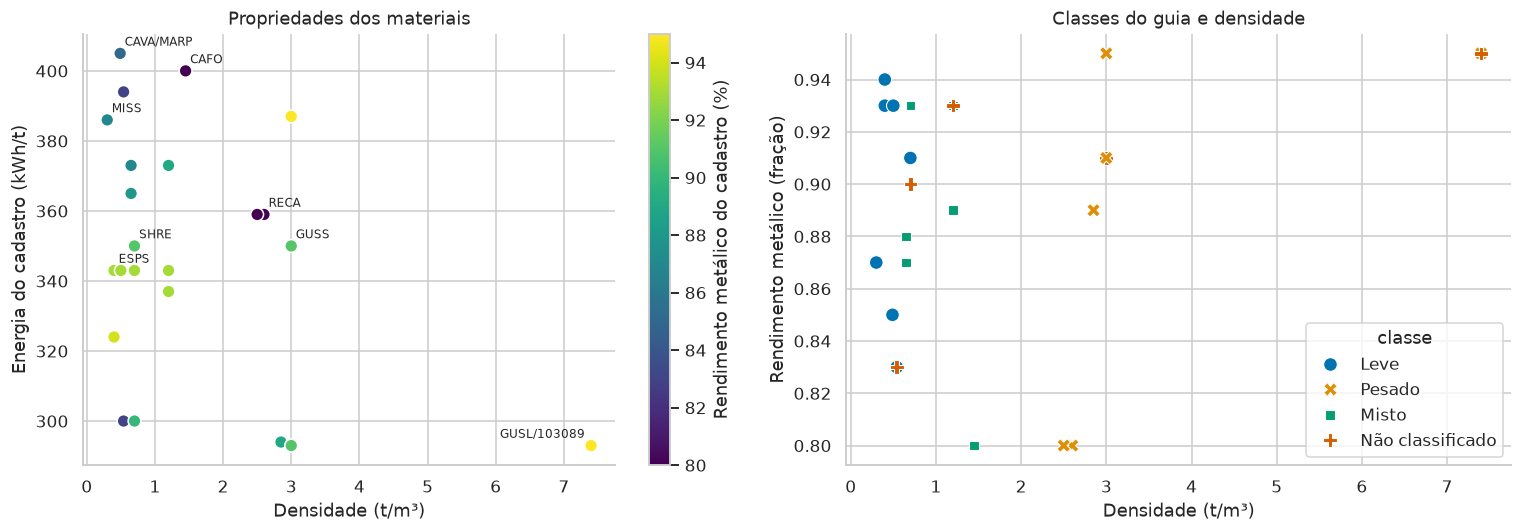

In [5]:
metallic = materials.loc[~materials['is_input']].copy()
display(materials.sort_values(['is_input', 'density_t_m3', 'material_code']))
display(metallic.groupby('class').agg(materials=('material_code', 'size'),
    density_min=('density_t_m3', 'min'), density_mean=('density_t_m3', 'mean'),
    density_max=('density_t_m3', 'max'), energy_mean=('energy_kwh_t', 'mean'),
    yield_mean=('yield_fraction', 'mean')))
display(Markdown(f'O cadastro contém **{len(metallic)} materiais metálicos** e '
                 f'**{materials.is_input.sum()} insumos não metálicos**. '
                 f'O material de menor densidade é **{metallic.loc[metallic.density_t_m3.idxmin(), "material_code"]}**.'))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sc = axes[0].scatter(metallic['density_t_m3'], metallic['energy_kwh_t'],
                     c=metallic['yield_fraction'] * 100, cmap='viridis', s=70, edgecolor='white')
# Identificar materiais de referência; pontos coincidentes compartilham o rótulo.
# A tabela acima contém o cadastro completo.
landmarks = {'MISS', 'ESPS', 'SHRE', 'CAVA', 'CAFO', 'RECA', 'GUSS', 'GUSL'}
annotations = metallic.groupby(['density_t_m3', 'energy_kwh_t'])['material_code'].agg('/'.join).reset_index()
for _, row in annotations.iterrows():
    if landmarks.intersection(row.material_code.split('/')):
        liquid = row.density_t_m3 > 7
        axes[0].annotate(row.material_code, (row.density_t_m3, row.energy_kwh_t),
                         xytext=(-4 if liquid else 3, 5), textcoords='offset points',
                         ha='right' if liquid else 'left', fontsize=8)
fig.colorbar(sc, ax=axes[0], label='Rendimento metálico do cadastro (%)')
axes[0].set(xlabel='Densidade (t/m³)', ylabel='Energia do cadastro (kWh/t)', title='Propriedades dos materiais')
sns.scatterplot(data=metallic.assign(classe=metallic['class'].map(CLASS_LABELS)),
                x='density_t_m3', y='yield_fraction', hue='classe', style='classe', s=80, ax=axes[1])
axes[1].set(xlabel='Densidade (t/m³)', ylabel='Rendimento metálico (fração)', title='Classes do guia e densidade')
mostrar_graficos()


## 3. Estrutura e composição dos carregamentos

O resumo de peso inclui todos os carregamentos registrados. A composição dos cestos usa **pesos positivos nos carregamentos 1 e 2**. Registros na mesma posição podem representar materiais diferentes; pesos zero não criam camadas ativas.


nu_carregamento                  1         2         3
weight_t           count 1,799.000 1,702.000 1,436.000
                   mean     58.308    35.957    37.029
                   std       5.658    11.874    11.011
                   min      29.720    12.210    22.700
                   25%      54.040    27.883    31.200
                   50%      58.080    32.345    34.300
                   75%      62.060    38.615    37.000
                   max      78.450    66.750   114.100
records            count 1,799.000 1,702.000 1,436.000
                   mean     14.551     9.177     1.118
                   std       1.761     2.246     0.573
                   min       7.000     5.000     1.000
                   25%      14.000     8.000     1.000
                   50%      15.000     8.000     1.000
                   75%      16.000    10.000     1.000
                   max      20.000    17.000    10.000
recorded_positions count 1,799.000 1,702.000 1,436.000
                   mean     14.548     9.176     1.106
                   std       1.763     2.245     0.540
                   min       7.000     5.000     1.000
                   25%      14.000     8.000     1.000
                   50%      15.000     8.000     1.000
                   75%      16.000    10.000     1.000
                   max      20.000    17.000     9.000

,records,weight_t
cd_codigo_material,,
118441,1,2.000
194032,5,22.530
ESPS,9,32.850
GUSL,1561,"53,006.150"
GUSS,4,21.020
MISM,2,4.190
OXIC,5,8.710
PACB,2,9.620
PAEP,4,7.050


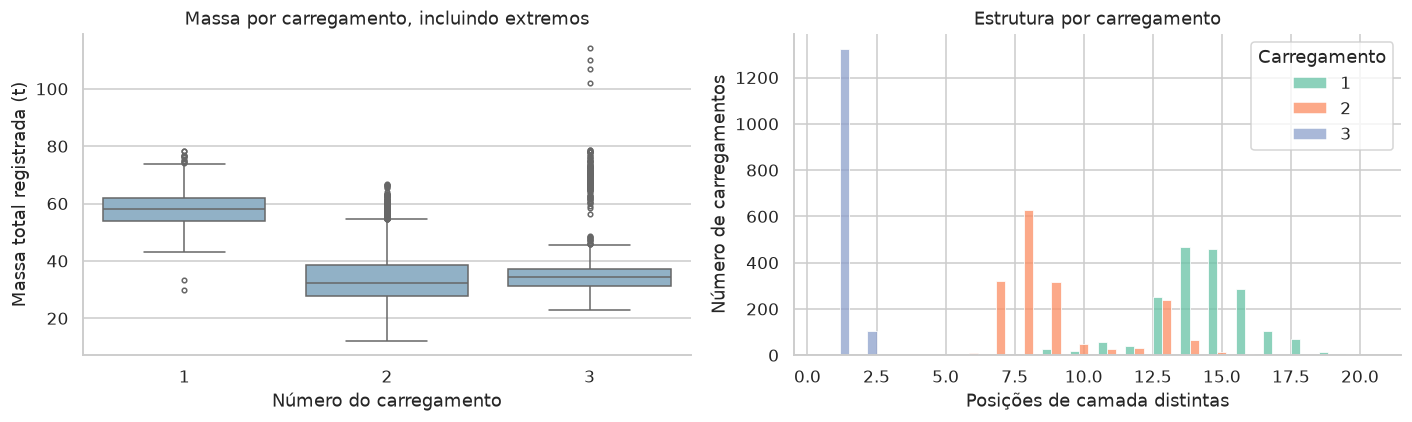

,,weight_t,records,heats,mean_layer_t
cd_codigo_material,ds_descricao_material,,,,
GUSL,GUSA LIQUIDO,"53,006.150",1561,1436,33.957
GUSS,GUSA SOLIDO,"32,082.860",6720,1337,4.774
OXIC,SUCATA OXICORTADA,"29,176.290",7278,1731,4.009
SHRE,SHREDDER,"28,457.335",6191,1797,4.597
MISM,SUCATA MIUDA,"16,434.650",4101,1430,4.007
ESPS,ESTAMPARIA PRETA SOLTA,"10,595.520",2744,1142,3.861
PAEP,PACOTE DE ESTAMPARIA PRETA,"10,407.550",2365,992,4.401
194032,GUSA SOLIDO PRODUCAO INTERNA,"8,382.100",1643,424,5.102
CAVA,CAVACO DE ACO,"6,225.650",1318,1300,4.724


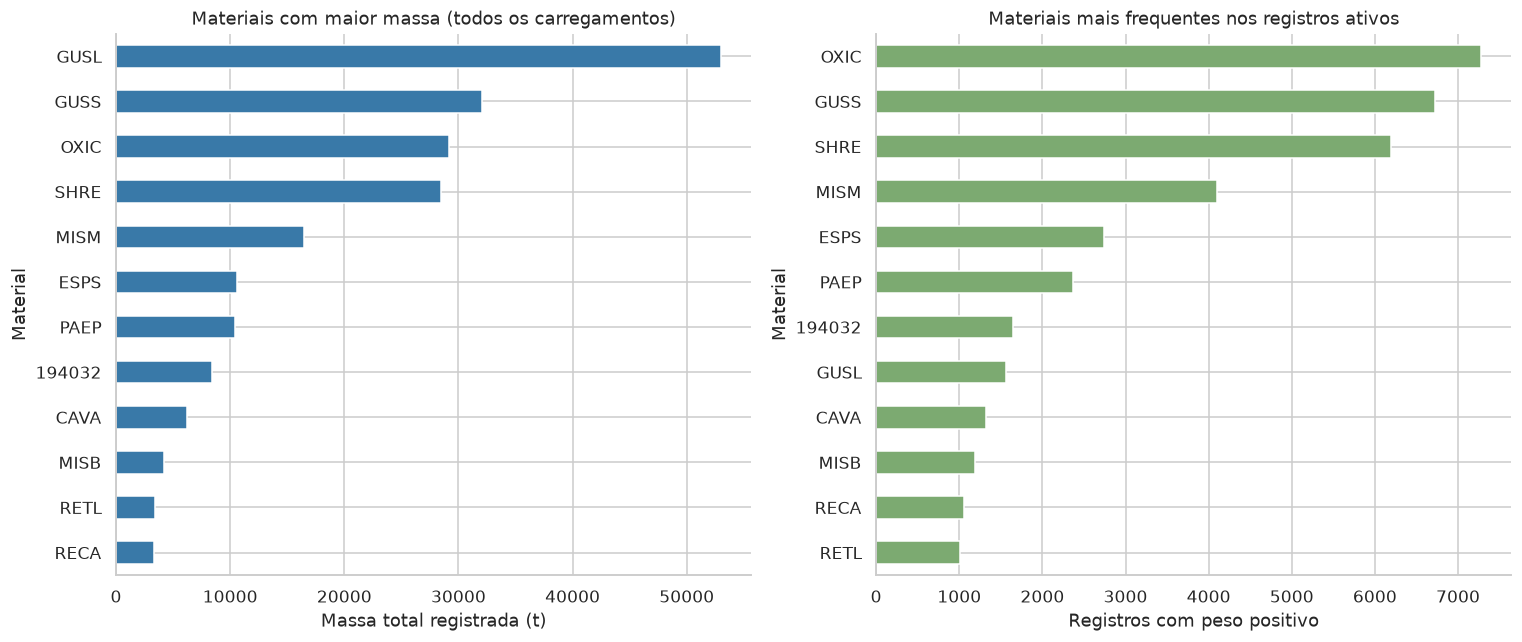

nu_carregamento,1,2
cd_codigo_material,,
OXIC,17.628,17.446
SHRE,16.988,17.292
GUSS,16.571,23.987
MISM,8.223,12.753
PAEP,6.108,6.526
CAVA,5.935,0.000
ESPS,5.820,7.284
194032,4.299,6.291
RECA,3.170,0.003


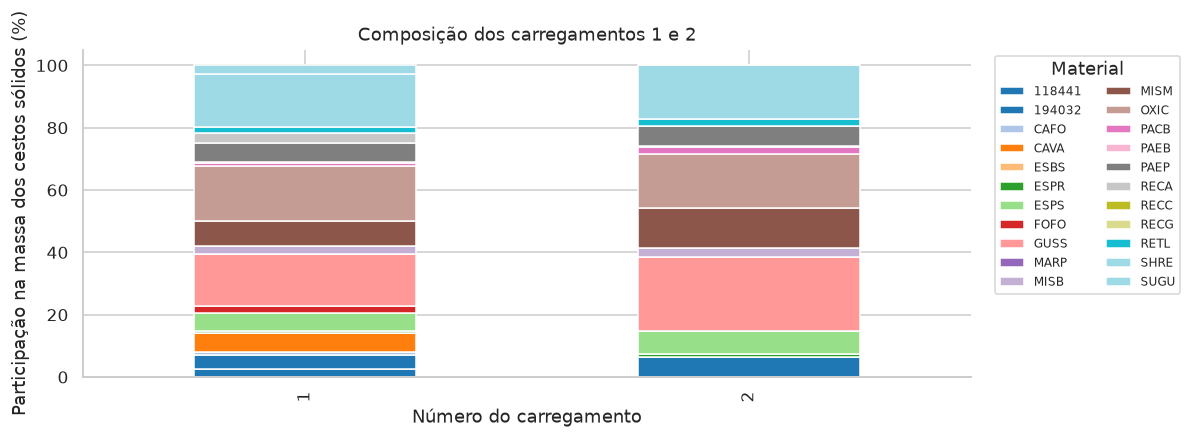

In [6]:
all_charges = enriched.groupby(['cd_corrida', 'nu_carregamento']).agg(
    weight_t=('weight_t', 'sum'), records=('nu_camada', 'size'),
    recorded_positions=('nu_camada', 'nunique'), materials=('cd_codigo_material', 'nunique')).reset_index()
display(all_charges.groupby('nu_carregamento')[['weight_t', 'records', 'recorded_positions']].describe().T)
display(enriched.loc[enriched['nu_carregamento'] == 3].groupby('cd_codigo_material').agg(
    records=('weight_t', 'size'), weight_t=('weight_t', 'sum')))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=all_charges, x='nu_carregamento', y='weight_t', ax=axes[0], color='#88b3cf', fliersize=3)
axes[0].set(xlabel='Número do carregamento', ylabel='Massa total registrada (t)', title='Massa por carregamento, incluindo extremos')
sns.histplot(data=all_charges, x='recorded_positions', hue='nu_carregamento', discrete=True,
             multiple='dodge', ax=axes[1], palette='Set2')
axes[1].set(xlabel='Posições de camada distintas', title='Estrutura por carregamento', ylabel='Número de carregamentos')
mostrar_graficos()

material_use = enriched.loc[enriched['weight_t'] > 0].groupby(['cd_codigo_material', 'ds_descricao_material']).agg(
    weight_t=('weight_t', 'sum'), records=('weight_t', 'size'),
    heats=('cd_corrida', 'nunique'), mean_layer_t=('weight_t', 'mean')).sort_values('weight_t', ascending=False)
display(material_use)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
material_use.head(12).sort_values('weight_t')['weight_t'].droplevel(1).plot.barh(ax=axes[0], color='#3979a8')
axes[0].set(xlabel='Massa total registrada (t)', ylabel='Material', title='Materiais com maior massa (todos os carregamentos)')
material_use.sort_values('records').tail(12)['records'].droplevel(1).plot.barh(ax=axes[1], color='#7caa71')
axes[1].set(xlabel='Registros com peso positivo', ylabel='Material', title='Materiais mais frequentes nos registros ativos')
mostrar_graficos()

active = enriched.loc[enriched['nu_carregamento'].isin([1, 2]) & enriched['weight_t'].gt(0)].copy()
keys = ['cd_corrida', 'nu_carregamento']
composition = active.groupby(['nu_carregamento', 'cd_codigo_material'])['weight_t'].sum().unstack(fill_value=0)
composition_pct = composition.div(composition.sum(axis=1), axis=0) * 100
display(composition_pct.T.sort_values(1, ascending=False))
composition_pct.plot.bar(stacked=True, figsize=(11, 4), colormap='tab20')
plt.ylabel('Participação na massa dos cestos sólidos (%)')
plt.xlabel('Número do carregamento')
plt.title('Composição dos carregamentos 1 e 2')
plt.legend(title='Material', bbox_to_anchor=(1.02, 1), loc='upper left', ncol=2, fontsize=8)
mostrar_graficos()


## 4. Volume estimado e ordem das camadas

O volume é a soma de `peso_t / densidade_t_m3`; a **densidade efetiva** é a massa total dividida por esse volume. Essas estimativas não medem compactação, expansão da sucata ou capacidade real do forno.

Se faltar densidade para parte da massa, o volume completo fica ausente. O volume conhecido e a cobertura de massa são mantidos; energia e rendimento ponderados seguem a mesma regra.

As posições ocupadas são ordenadas da base (0) ao topo (1); um cesto com uma única posição recebe 0,5. As proporções de material leve na base, no topo e no terço central são indicadores descritivos de montagem, não violações de uma regra operacional validada.


10 cestos observados têm cobertura incompleta de densidade.


,baskets,weight_mean_t,weight_median_t,layers_median,volume_mean_m3,density_coverage_mean
nu_carregamento,,,,,,
1,1799,58.308,58.080,14.000,70.756,1.000
2,1702,35.957,32.345,8.000,43.829,1.000


class                           Heavy  Light  Mixed  Unclassified
nu_carregamento position_zone                                    
1               Terço inferior 26.204 43.174 30.586         0.037
                Terço central  36.252 15.801 47.909         0.038
                Terço superior 33.328 34.834 31.830         0.008
2               Terço inferior 19.913 32.197 47.890         0.000
                Terço central  47.615 10.043 42.342         0.000
                Terço superior 26.338 44.258 29.404         0.000

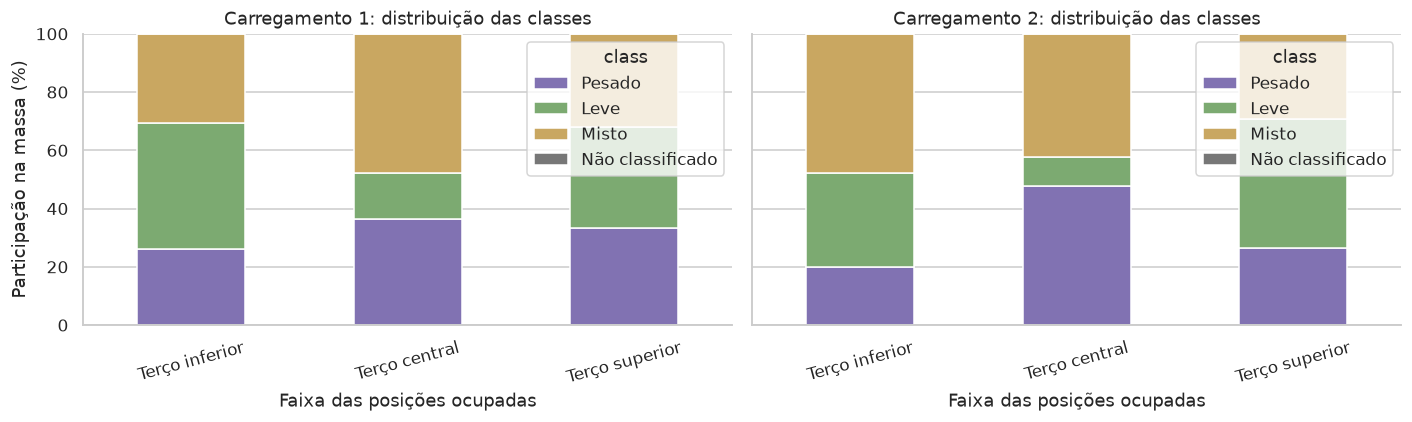

In [7]:
active['volume_known_m3'] = active['weight_t'] / active['density_t_m3']
active['density_known_weight_t'] = active['weight_t'].where(active['density_t_m3'].notna(), 0)
active['energy_known_weight_t'] = active['weight_t'].where(active['energy_kwh_t'].notna(), 0)
active['yield_known_weight_t'] = active['weight_t'].where(active['yield_fraction'].notna(), 0)
active['energy_est_kwh'] = active['weight_t'] * active['energy_kwh_t']
active['yield_est_t'] = active['weight_t'] * active['yield_fraction']

active['position_rank'] = active.groupby(keys)['nu_camada'].rank(method='dense')
active['active_positions'] = active.groupby(keys)['nu_camada'].transform('nunique')
active['relative_position'] = ((active['position_rank'] - 1) / (active['active_positions'] - 1)).fillna(0.5)
active['position_zone'] = pd.cut(active['relative_position'], [-0.001, 1/3, 2/3, 1.001],
                                 labels=['Terço inferior', 'Terço central', 'Terço superior'])

def aggregate_features(frame, group_keys):
    grouped = frame.groupby(group_keys)
    result = grouped.agg(
        weight_t=('weight_t', 'sum'), active_records=('weight_t', 'size'),
        material_count=('cd_codigo_material', 'nunique'),
        known_density_weight_t=('density_known_weight_t', 'sum'),
        known_energy_weight_t=('energy_known_weight_t', 'sum'),
        known_yield_weight_t=('yield_known_weight_t', 'sum'),
    )
    # min_count impede que uma soma totalmente desconhecida vire zero.
    result['volume_known_m3'] = grouped['volume_known_m3'].sum(min_count=1)
    result['density_coverage'] = result['known_density_weight_t'] / result['weight_t']
    result['volume_est_m3'] = result['volume_known_m3'].where(np.isclose(result['density_coverage'], 1))
    result['effective_density_t_m3'] = result['weight_t'] / result['volume_est_m3']
    for name, col in [('energy', 'energy_est_kwh'), ('yield', 'yield_est_t')]:
        coverage = result[f'known_{name}_weight_t'] / result['weight_t']
        result[f'{name}_coverage'] = coverage
        result['energy_weighted_kwh_t' if name == 'energy' else 'yield_weighted_fraction'] = (
            grouped[col].sum(min_count=1) / result['weight_t']).where(np.isclose(coverage, 1))
    class_weights = frame.groupby(group_keys + ['class'])['weight_t'].sum().unstack(fill_value=0)
    for cls in ['Light', 'Heavy', 'Mixed', 'Unclassified']:
        result[f'{cls.lower()}_weight_t'] = class_weights.get(cls, pd.Series(0, index=result.index))
        result[f'{cls.lower()}_share'] = result[f'{cls.lower()}_weight_t'] / result['weight_t']
    assert np.allclose(result[[f'{c}_share' for c in ['light', 'heavy', 'mixed', 'unclassified']]].sum(axis=1), 1)
    return result

basket_features = aggregate_features(active, keys)
basket_features['layer_count'] = active.groupby(keys)['nu_camada'].nunique()
light_weight = active['weight_t'].where(active['class'] == 'Light', 0)
for side, condition in [('bottom', active['position_rank'] == 1),
                        ('top', active['position_rank'] == active['active_positions'])]:
    denominator = active.loc[condition].groupby(keys)['weight_t'].sum()
    numerator = active.assign(light_weight_t=light_weight).loc[condition].groupby(keys)['light_weight_t'].sum()
    basket_features[f'{side}_light_share'] = numerator / denominator
middle_light = active.assign(middle_light_weight_t=light_weight.where(
    active['position_zone'] == 'Terço central', 0)).groupby(keys)['middle_light_weight_t'].sum()
basket_features['middle_light_share_total'] = middle_light / basket_features['weight_t']
display(basket_features.groupby('nu_carregamento').agg(
    baskets=('weight_t', 'size'), weight_mean_t=('weight_t', 'mean'),
    weight_median_t=('weight_t', 'median'), layers_median=('layer_count', 'median'),
    volume_mean_m3=('volume_est_m3', 'mean'), density_coverage_mean=('density_coverage', 'mean')))
print(f'{basket_features.volume_est_m3.isna().sum()} cestos observados têm cobertura incompleta de densidade.')

position_mass = active.groupby(['nu_carregamento', 'position_zone', 'class'], observed=True)['weight_t'].sum()
position_share = position_mass.unstack(fill_value=0)
position_share = position_share.div(position_share.sum(axis=1), axis=0) * 100
display(position_share)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for i, ax in zip([1, 2], axes):
    position_share.loc[i].rename(columns=CLASS_LABELS).plot.bar(stacked=True, ax=ax, color=['#8172b2', '#7caa71', '#c9a761', '#777777'])
    ax.set(title=f'Carregamento {i}: distribuição das classes', xlabel='Faixa das posições ocupadas', ylabel='Participação na massa (%)')
    ax.tick_params(axis='x', rotation=15)
mostrar_graficos()


## 5. Frequência de carga alta e tempo de parada

As taxas iniciais usam todos os rótulos da resposta, inclusive os que não têm camadas correspondentes. As comparações com características dos cestos usam apenas cestos observados e informam seus denominadores.

Os intervalos de confiança de 95% usam o método de Wilson. Eles não corrigem dependência temporal nem possíveis vieses da amostra.


,n,events,rate,ci_low,ci_high
scope,,,,,
Carga alta na corrida,1799,541,0.301,0.280,0.322
Carregamento 1,1799,258,0.143,0.128,0.160
Carregamento 2,1799,308,0.171,0.155,0.189


Evento no carregamento 2,0,1
Evento no carregamento 1,,
0,1258,283
1,233,25


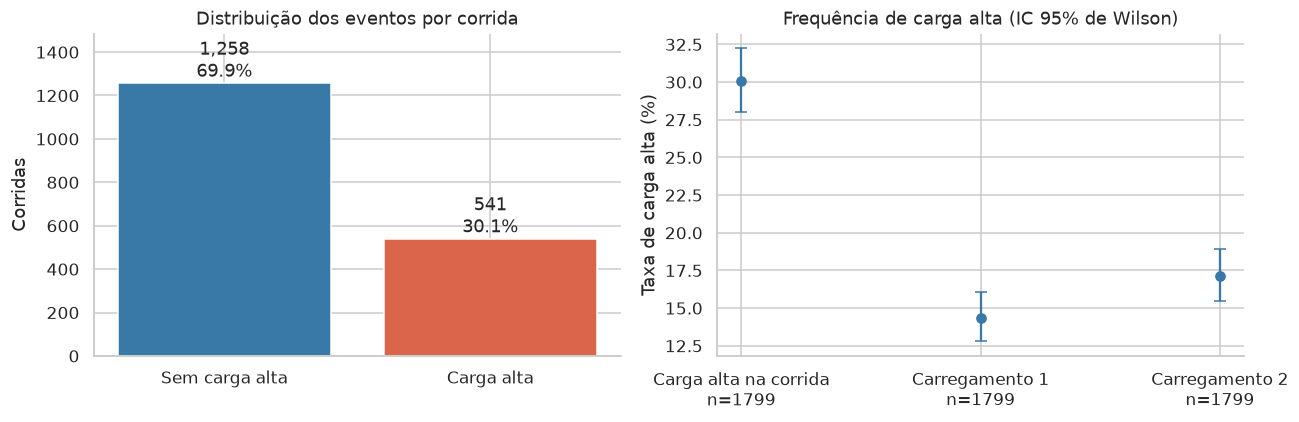

,Segundos por corrida afetada
count,541.000
mean,244.835
std,206.934
min,16.000
50%,181.000
75%,322.000
90%,502.000
95%,714.000
99%,997.800
max,"1,244.000"


,charge,positive_events,total_minutes,median_positive_seconds
0,1,258,"1,012.600",169.000
1,2,308,"1,195.000",172.500


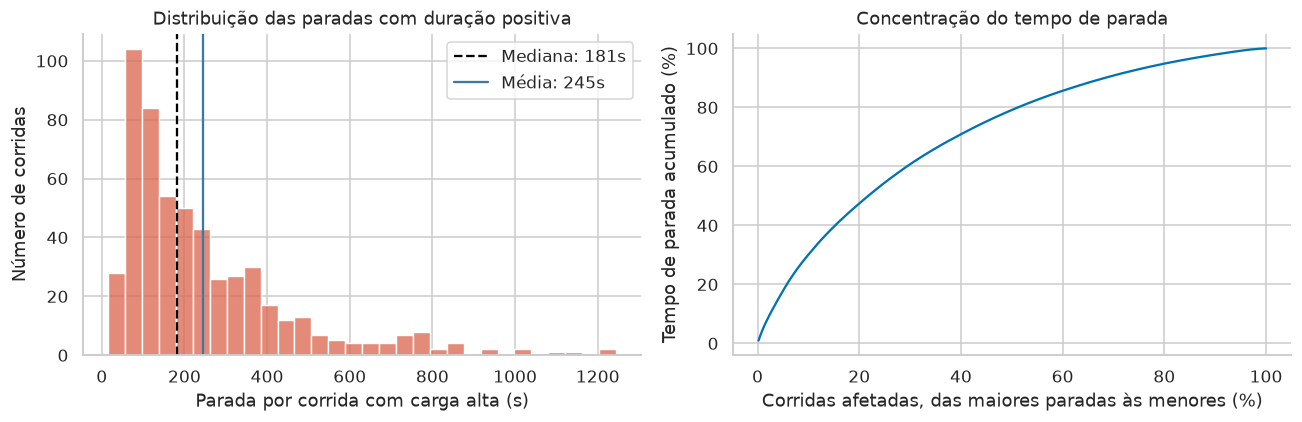

Parada total observada: **2,207.6 minutes (36.79 horas)** na amostra fornecida. O total se refere somente a esta amostra.

,avoided_downtime_fraction,minutes_saved_in_sample
0,0.100,220.760
1,0.250,551.900
2,0.500,"1,103.800"


In [8]:
def wilson(k, n, z=1.96):
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    p = np.divide(k, n, out=np.full_like(k, np.nan), where=n > 0)
    denom = 1 + z*z / n
    center = (p + z*z / (2*n)) / denom
    half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / denom
    return center - half, center + half

def rate_table(frame, group_col, target='is_carga_alta'):
    result = frame.groupby(group_col, observed=True)[target].agg(n='count', events='sum', rate='mean')
    result['ci_low'], result['ci_high'] = wilson(result['events'], result['n'])
    return result

def plot_rates(table, ax, title, baseline=None):
    x = np.arange(len(table))
    ax.errorbar(x, table['rate'] * 100,
                yerr=np.vstack([(table['rate'] - table['ci_low']) * 100,
                                (table['ci_high'] - table['rate']) * 100]),
                fmt='o', capsize=4, color='#3979a8')
    labels = [f'{label.left:.1f}–{label.right:.1f}' if isinstance(label, pd.Interval) else str(label)
              for label in table.index]
    ax.set_xticks(x, [f'{label}\nn={int(n)}' for label, n in zip(labels, table['n'])])
    ax.set(title=title, ylabel='Taxa de carga alta (%)')
    if baseline is not None:
        ax.axhline(baseline * 100, linestyle='--', color='gray', linewidth=1, label='Média do grupo')
        ax.legend(fontsize=8)

prevalence = pd.DataFrame([{'scope': name, 'n': len(response), 'events': response[col].sum(),
                           'rate': response[col].mean()} for name, col in
                          [('Carga alta na corrida', 'is_carga_alta'),
                           ('Carregamento 1', 'is_carga_alta_carregamento_1'),
                           ('Carregamento 2', 'is_carga_alta_carregamento_2')]]).set_index('scope')
prevalence['ci_low'], prevalence['ci_high'] = wilson(prevalence['events'], prevalence['n'])
display(prevalence)
display(pd.crosstab(response['is_carga_alta_carregamento_1'], response['is_carga_alta_carregamento_2'],
                    rownames=['Evento no carregamento 1'], colnames=['Evento no carregamento 2']))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = response['is_carga_alta'].value_counts().sort_index()
axes[0].bar(['Sem carga alta', 'Carga alta'], counts, color=[PALETTE[0], PALETTE[1]])
for x, count in enumerate(counts):
    axes[0].text(x, count, f'{count:,}\n{count/len(response):.1%}', ha='center', va='bottom')
axes[0].set(ylabel='Corridas', title='Distribuição dos eventos por corrida', ylim=(0, counts.max()*1.18))
plot_rates(prevalence, axes[1], 'Frequência de carga alta (IC 95% de Wilson)')
mostrar_graficos()

positive_stops = response.loc[response['is_carga_alta'] == 1, 'qt_segundos_parada_carga_alta']
downtime_minutes = response['qt_segundos_parada_carga_alta'].sum() / 60
display(positive_stops.describe(percentiles=[.5, .75, .9, .95, .99]).to_frame('Segundos por corrida afetada'))
display(pd.DataFrame([{'charge': i,
    'positive_events': response[f'is_carga_alta_carregamento_{i}'].sum(),
    'total_minutes': response[f'qt_segundos_duracao_parada_carregamento_{i}'].sum()/60,
    'median_positive_seconds': response.loc[response[f'is_carga_alta_carregamento_{i}'] == 1,
        f'qt_segundos_duracao_parada_carregamento_{i}'].median()} for i in [1, 2]]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(positive_stops, bins=30, ax=axes[0], color=PALETTE[1])
axes[0].set_ylabel('Número de corridas')
axes[0].axvline(positive_stops.median(), color='black', linestyle='--', label=f'Mediana: {positive_stops.median():.0f}s')
axes[0].axvline(positive_stops.mean(), color='#3979a8', label=f'Média: {positive_stops.mean():.0f}s')
axes[0].set(xlabel='Parada por corrida com carga alta (s)', title='Distribuição das paradas com duração positiva')
axes[0].legend()
sorted_stops = np.sort(positive_stops.to_numpy())[::-1]
axes[1].plot(np.arange(1, len(sorted_stops)+1)/len(sorted_stops)*100,
             np.cumsum(sorted_stops)/sorted_stops.sum()*100)
axes[1].set(xlabel='Corridas afetadas, das maiores paradas às menores (%)', ylabel='Tempo de parada acumulado (%)', title='Concentração do tempo de parada')
mostrar_graficos()
display(Markdown(f'Parada total observada: **{downtime_minutes:,.1f} minutes '
                 f'({downtime_minutes/60:,.2f} horas)** na amostra fornecida. '
                 'O total se refere somente a esta amostra.'))

# Cenários ilustrativos de redução do tempo de parada; não estimam efeito de uma intervenção.
# O custo por minuto deve ser validado pela equipe antes de calcular economia.
COST_PER_MINUTE_BRL = None  # Preencher com um custo validado pela equipe.
scenarios = pd.DataFrame({'avoided_downtime_fraction': [0.10, 0.25, 0.50]})
scenarios['minutes_saved_in_sample'] = scenarios['avoided_downtime_fraction'] * downtime_minutes
if COST_PER_MINUTE_BRL is not None:
    scenarios['estimated_savings_brl'] = scenarios['minutes_saved_in_sample'] * COST_PER_MINUTE_BRL
display(scenarios)


## 6. Características dos cestos e carga alta

Cada cesto recebe o evento do **mesmo carregamento**. A junção externa revela cestos ausentes; as associações usam somente cestos com características observadas e são calculadas separadamente para os carregamentos 1 e 2. Cestos de uma mesma corrida são dependentes.

As correlações, faixas de volume e indicadores de montagem são exploratórios. Diferenças podem refletir receita, massa ou período; não demonstram que alterar a ordem das camadas reduzirá os eventos.


In [9]:
charge_labels = pd.concat([response[['cd_corrida', f'is_carga_alta_carregamento_{i}',
                                    f'qt_segundos_duracao_parada_carregamento_{i}']].rename(columns={
    f'is_carga_alta_carregamento_{i}': 'is_carga_alta',
    f'qt_segundos_duracao_parada_carregamento_{i}': 'downtime_seconds'}).assign(nu_carregamento=i)
    for i in [1, 2]], ignore_index=True)
basket_join = charge_labels.merge(basket_features.reset_index(), on=keys, how='outer',
                                  validate='one_to_one', indicator='feature_match')
display(basket_join.groupby(['nu_carregamento', 'feature_match'], observed=True).agg(
    rows=('cd_corrida', 'size'), events=('is_carga_alta', 'sum')))
assert not basket_join['feature_match'].eq('right_only').any()
baskets = basket_join.loc[basket_join['feature_match'] == 'both'].copy()
display(rate_table(baskets, 'nu_carregamento'))

features = ['weight_t', 'volume_est_m3', 'effective_density_t_m3', 'layer_count',
            'material_count', 'light_share', 'heavy_share', 'mixed_share',
            'bottom_light_share', 'top_light_share', 'middle_light_share_total',
            'energy_weighted_kwh_t', 'yield_weighted_fraction']

# Correlação ponto-bisserial: correlação de Pearson com uma resposta binária.
association_rows = []
for charge, group in baskets.groupby('nu_carregamento'):
    for feature in features:
        pair = group[[feature, 'is_carga_alta']].dropna()
        neg = pair.loc[pair['is_carga_alta'] == 0, feature]
        pos = pair.loc[pair['is_carga_alta'] == 1, feature]
        association_rows.append({'charge': charge, 'feature': feature, 'n': len(pair),
            'events': int(pair.is_carga_alta.sum()), 'mean_no_event': neg.mean(),
            'mean_event': pos.mean(), 'median_no_event': neg.median(), 'median_event': pos.median(),
            'mean_difference': pos.mean()-neg.mean(),
            'mean_difference_pct': 100*(pos.mean()/neg.mean()-1) if neg.mean() != 0 else np.nan,
            'point_biserial_r': pair[feature].corr(pair['is_carga_alta'])})
associations = pd.DataFrame(association_rows)
associations['abs_r'] = associations['point_biserial_r'].abs()
display(associations.sort_values(['charge', 'abs_r'], ascending=[True, False]).drop(columns='abs_r'))


rows  events
nu_carregamento feature_match              
1               both           1799     258
2               left_only        97       7
                both           1702     301

,n,events,rate,ci_low,ci_high
nu_carregamento,,,,,
1,1799,258,0.143,0.128,0.160
2,1702,301,0.177,0.159,0.196


,charge,feature,n,events,mean_no_event,mean_event,median_no_event,median_event,mean_difference,mean_difference_pct,point_biserial_r
6,1,heavy_share,1799,258,0.320,0.268,0.321,0.290,-0.052,-16.146,-0.186
3,1,layer_count,1799,258,14.218,13.391,14.000,14.000,-0.827,-5.814,-0.168
0,1,weight_t,1799,258,58.694,56.002,58.480,56.040,-2.691,-4.585,-0.167
2,1,effective_density_t_m3,1789,255,0.841,0.792,0.842,0.801,-0.049,-5.827,-0.162
5,1,light_share,1799,258,0.315,0.361,0.298,0.344,0.046,14.590,0.150
10,1,middle_light_share_total,1799,258,0.048,0.059,0.032,0.059,0.011,23.848,0.068
12,1,yield_weighted_fraction,1789,255,0.893,0.892,0.893,0.891,-0.002,-0.193,-0.051
4,1,material_count,1799,258,8.430,8.244,9.000,8.000,-0.185,-2.199,-0.044
8,1,bottom_light_share,1799,258,0.935,0.903,1.000,1.000,-0.032,-3.423,-0.044
9,1,top_light_share,1799,258,0.992,1.000,1.000,1.000,0.008,0.817,0.035


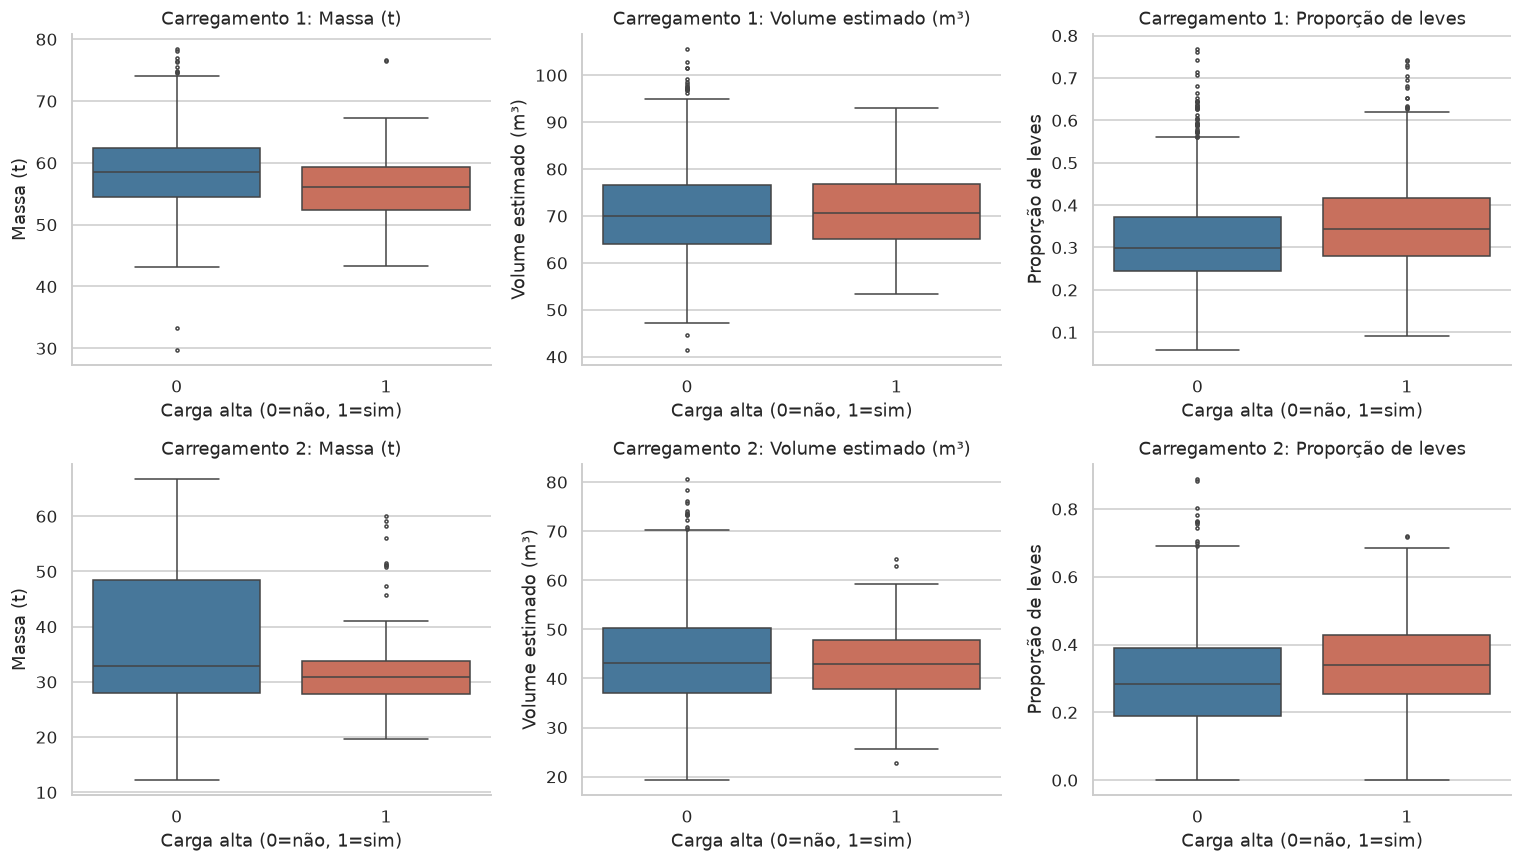

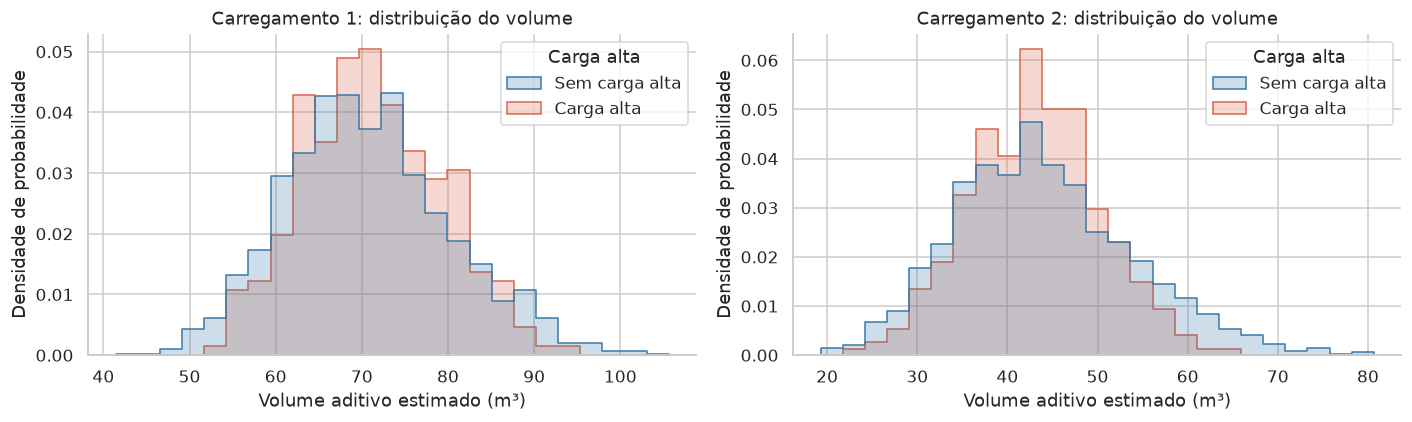

,volume_bin,n,events,rate,ci_low,ci_high,charge
0,"(41.429, 62.761]",358,41,0.115,0.086,0.152,1
1,"(62.761, 67.786]",358,48,0.134,0.103,0.173,1
2,"(67.786, 72.664]",357,62,0.174,0.138,0.216,1
3,"(72.664, 78.627]",358,55,0.154,0.120,0.195,1
4,"(78.627, 105.608]",358,49,0.137,0.105,0.176,1
5,"(19.296999999999997, 35.658]",341,50,0.147,0.113,0.188,2
6,"(35.658, 40.937]",340,64,0.188,0.150,0.233,2
7,"(40.937, 45.377]",340,70,0.206,0.166,0.252,2
8,"(45.377, 51.604]",340,79,0.232,0.191,0.280,2
9,"(51.604, 80.642]",341,38,0.111,0.082,0.149,2


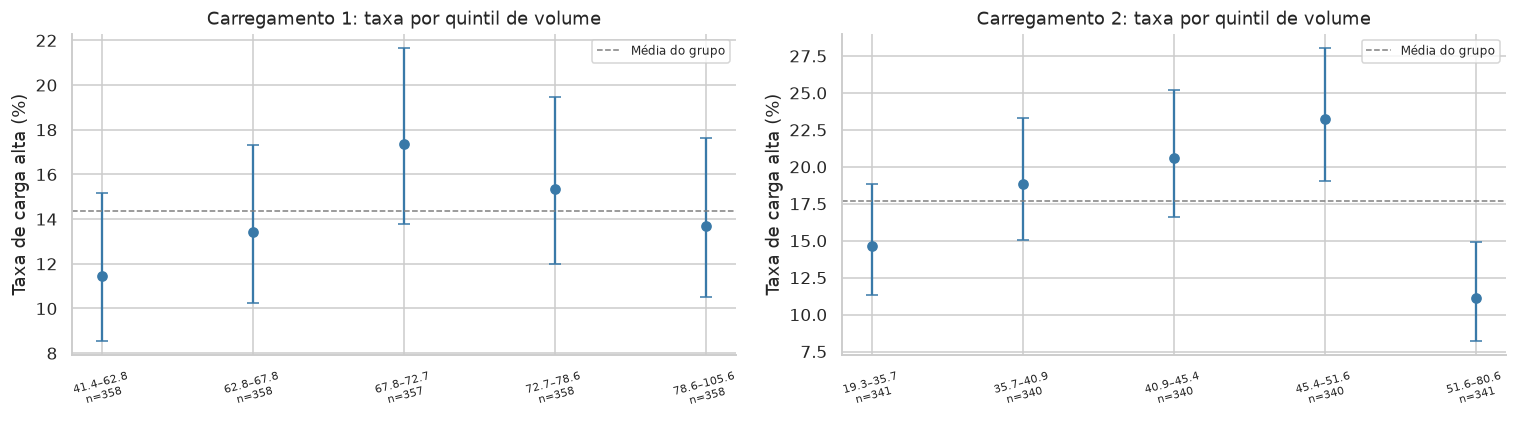

,light_at_both_ends,n,events,rate,ci_low,ci_high,charge
0,False,134,25,0.187,0.130,0.261,1
1,True,1665,233,0.140,0.124,0.157,1
2,False,613,97,0.158,0.131,0.189,2
3,True,1089,204,0.187,0.165,0.212,2


In [10]:
plot_features = ['weight_t', 'volume_est_m3', 'light_share']
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for row, charge in enumerate([1, 2]):
    for ax, feature in zip(axes[row], plot_features):
        label = FEATURE_LABELS[feature]
        sns.boxplot(data=baskets.loc[baskets.nu_carregamento == charge], x='is_carga_alta', y=feature,
                    hue='is_carga_alta', palette=PALETTE, legend=False, ax=ax, fliersize=2)
        ax.set(title=f'Carregamento {charge}: {label}', xlabel='Carga alta (0=não, 1=sim)', ylabel=label)
mostrar_graficos()

# Normalizar cada classe separadamente para comparar as distribuições.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for charge, ax in zip([1, 2], axes):
    subset = baskets.loc[baskets.nu_carregamento == charge]
    sns.histplot(data=subset, x='volume_est_m3', hue='is_carga_alta', stat='density',
                 common_norm=False, element='step', bins=25, palette=PALETTE, ax=ax)
    ax.set(title=f'Carregamento {charge}: distribuição do volume', xlabel='Volume aditivo estimado (m³)', ylabel='Densidade de probabilidade')
mostrar_graficos()

volume_bins = []
for charge, group in baskets.dropna(subset=['volume_est_m3']).groupby('nu_carregamento'):
    group = group.copy()
    group['volume_bin'] = pd.qcut(group['volume_est_m3'], 5, duplicates='drop')
    table = rate_table(group, 'volume_bin')
    table['charge'] = charge
    volume_bins.append(table.reset_index())
volume_risk = pd.concat(volume_bins, ignore_index=True)
display(volume_risk)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for charge, ax in zip([1, 2], axes):
    table = volume_risk.loc[volume_risk.charge == charge].set_index('volume_bin')
    plot_rates(table, ax, f'Carregamento {charge}: taxa por quintil de volume',
               baskets.loc[baskets.nu_carregamento == charge, 'is_carga_alta'].mean())
    ax.tick_params(axis='x', labelsize=7, rotation=15)
mostrar_graficos()

# Indicadores de montagem: informar os tamanhos dos grupos.
order_tables = []
for charge, group in baskets.groupby('nu_carregamento'):
    group = group.copy()
    group['light_at_both_ends'] = (group.bottom_light_share > 0) & (group.top_light_share > 0)
    table = rate_table(group, 'light_at_both_ends')
    table['charge'] = charge
    order_tables.append(table.reset_index())
display(pd.concat(order_tables, ignore_index=True))


### Presença e coocorrência dos materiais

Cada material é contado uma vez por cesto, considerando apenas registros ativos. Comparamos taxas com e sem o material quando ambos os grupos têm ao menos 30 cestos. Isso evita repetir o evento por camada, mas não elimina efeitos da receita, da massa ou do período. A coocorrência usa o índice de Jaccard.


,charge,material,exposed_n,exposed_events,exposed_rate,exposed_ci_low,exposed_ci_high,unexposed_n,unexposed_rate,difference_pp
14,1,PAEB,88,21,0.239,0.162,0.337,1711,0.139,10.012
4,1,ESBS,62,14,0.226,0.140,0.344,1737,0.140,8.533
6,1,ESPS,922,162,0.176,0.152,0.202,877,0.109,6.624
18,1,SUGU,773,139,0.180,0.154,0.208,1026,0.116,6.383
15,1,PAEP,838,140,0.167,0.143,0.194,961,0.123,4.428
13,1,PACB,244,44,0.180,0.137,0.233,1555,0.138,4.271
16,1,RECA,1054,169,0.160,0.139,0.184,745,0.119,4.088
12,1,OXIC,1667,237,0.142,0.126,0.160,132,0.159,-1.692
17,1,RETL,513,66,0.129,0.102,0.160,1286,0.149,-2.065
11,1,MISM,1249,171,0.137,0.119,0.157,550,0.158,-2.127


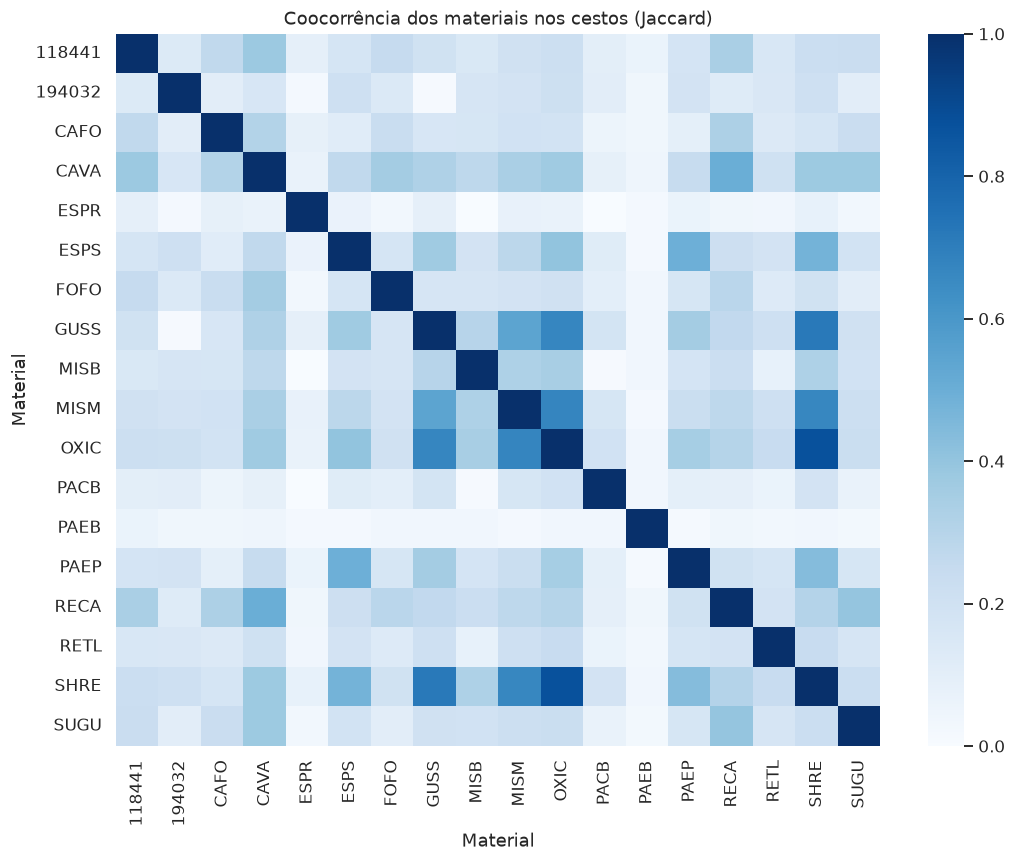

In [11]:
presence = active.groupby(keys + ['cd_codigo_material']).size().unstack(fill_value=0).gt(0).astype(int)
material_risk_rows = []
for charge in [1, 2]:
    frame = baskets.loc[baskets.nu_carregamento == charge].set_index('cd_corrida')
    exposures = presence.xs(charge, level='nu_carregamento').reindex(frame.index, fill_value=0)
    for material in exposures.columns:
        yes = frame.loc[exposures[material].eq(1), 'is_carga_alta']
        no = frame.loc[exposures[material].eq(0), 'is_carga_alta']
        if min(len(yes), len(no)) >= 30:
            low, high = wilson(yes.sum(), len(yes))
            material_risk_rows.append({'charge': charge, 'material': material,
                'exposed_n': len(yes), 'exposed_events': int(yes.sum()), 'exposed_rate': yes.mean(),
                'exposed_ci_low': float(low), 'exposed_ci_high': float(high),
                'unexposed_n': len(no), 'unexposed_rate': no.mean(),
                'difference_pp': (yes.mean()-no.mean())*100})
material_risk = pd.DataFrame(material_risk_rows)
display(material_risk.sort_values(['charge', 'difference_pp'], ascending=[True, False]))

common = presence.columns[presence.sum() >= 100]
co_counts = presence[common].T.dot(presence[common])
counts = presence[common].sum()
unions = counts.to_numpy()[:, None] + counts.to_numpy()[None, :] - co_counts.to_numpy()
jaccard = co_counts / unions
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(jaccard, cmap='Blues', vmin=0, vmax=1, ax=ax)
ax.set(title='Coocorrência dos materiais nos cestos (Jaccard)', xlabel='Material', ylabel='Material')
mostrar_graficos()


## 7. Consolidação por corrida e valores extremos

A tabela por corrida reúne os carregamentos 1 e 2 e mantém suas características separadas. **Totais de corridas com um cesto ausente são parciais**; `complete_two_baskets` identifica corridas completas. Características ausentes não viram zero.

As comparações principais usam corridas completas. Características dos dois cestos só podem prever o carregamento 1 se ambas as receitas já estiverem disponíveis naquele momento; horários de consumo também podem chegar tarde demais.


,n,events,rate,ci_low,ci_high
complete_two_baskets,,,,,
False,97,50,0.515,0.417,0.612
True,1702,491,0.288,0.267,0.310


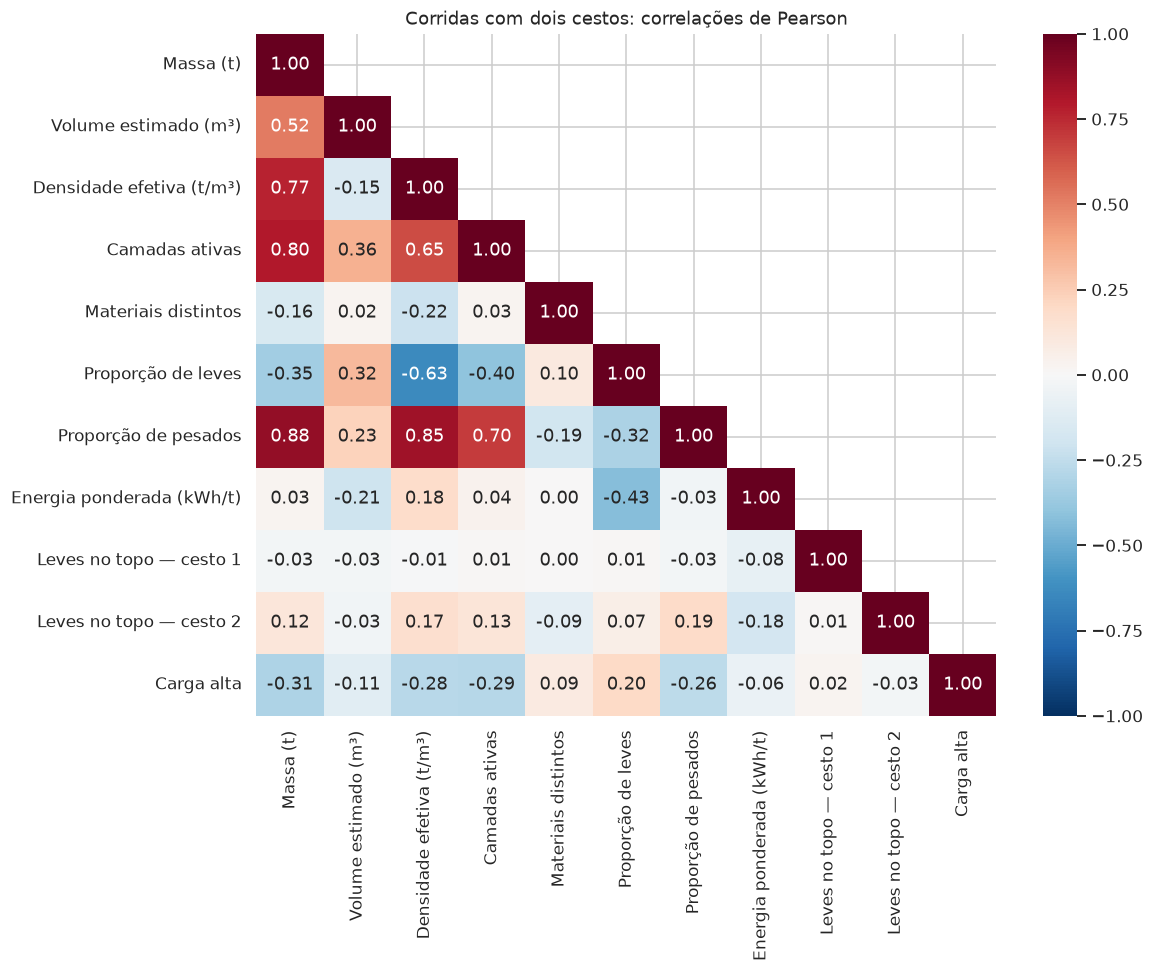

,r
solid_weight_t,-0.308
solid_layer_count,-0.288
solid_effective_density_t_m3,-0.275
solid_heavy_share,-0.258
solid_light_share,0.202
solid_volume_est_m3,-0.114
solid_material_count,0.089
solid_energy_weighted_kwh_t,-0.064
c2_top_light_share,-0.026
c1_top_light_share,0.025


,feature_1,feature_2,r
0,solid_weight_t,solid_layer_count,0.802
1,solid_weight_t,solid_heavy_share,0.882
2,solid_effective_density_t_m3,solid_heavy_share,0.848


In [12]:
heat_features = aggregate_features(active, ['cd_corrida']).add_prefix('solid_')
heat_features['solid_layer_count'] = active.drop_duplicates(keys + ['nu_camada']).groupby('cd_corrida').size()
heat_features['observed_basket_count'] = active.groupby('cd_corrida')['nu_carregamento'].nunique()
heat_features['complete_two_baskets'] = heat_features['observed_basket_count'].eq(2)
heat_features['recorded_all_charge_weight_t'] = enriched.groupby('cd_corrida')['weight_t'].sum()
heat_features['recorded_liquid_iron_weight_t'] = enriched.loc[enriched['cd_codigo_material'] == 'GUSL'].groupby(
    'cd_corrida')['weight_t'].sum().reindex(heat_features.index, fill_value=0)
heat_features['has_charge3_solid_records'] = heat_features.index.isin(charge3_anomalies.cd_corrida)
for charge in [1, 2]:
    per_charge = basket_features.xs(charge, level='nu_carregamento').add_prefix(f'c{charge}_')
    heat_features = heat_features.join(per_charge, validate='one_to_one')
heat_table = response.merge(heat_features.reset_index(), on='cd_corrida', how='left', validate='one_to_one')
assert len(heat_table) == len(response) and heat_table.cd_corrida.is_unique
display(rate_table(heat_table, 'complete_two_baskets'))
heat_cohort = heat_table.loc[heat_table['complete_two_baskets']].copy()
heat_predictors = ['solid_weight_t', 'solid_volume_est_m3', 'solid_effective_density_t_m3',
                   'solid_layer_count', 'solid_material_count', 'solid_light_share',
                   'solid_heavy_share', 'solid_energy_weighted_kwh_t',
                   'c1_top_light_share', 'c2_top_light_share']
heat_correlations = heat_cohort[heat_predictors + ['is_carga_alta']].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(heat_correlations.rename(index=FEATURE_LABELS, columns=FEATURE_LABELS), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
             mask=np.triu(np.ones_like(heat_correlations, dtype=bool), k=1), ax=ax)
ax.set_title('Corridas com dois cestos: correlações de Pearson')
mostrar_graficos()
display(heat_correlations['is_carga_alta'].drop('is_carga_alta').sort_values(key=abs, ascending=False).to_frame('r'))

# Identificar variáveis redundantes; o limiar é apenas diagnóstico.
redundant = []
for i, left in enumerate(heat_predictors):
    for right in heat_predictors[i+1:]:
        value = heat_correlations.loc[left, right]
        if abs(value) >= 0.8:
            redundant.append({'feature_1': left, 'feature_2': right, 'r': value})
display(pd.DataFrame(redundant, columns=['feature_1', 'feature_2', 'r']))


### Sensibilidade aos valores extremos

Marcamos massas e volumes fora de 1,5 × IQR, separadamente por carregamento. Os registros permanecem na análise principal; a comparação sem extremos mostra se poucas observações dominam a correlação com volume. Esses limites são diagnósticos, não critérios para excluir erros automaticamente.


In [13]:
baskets['iqr_extreme'] = False
outlier_rows = []
for charge, group in baskets.groupby('nu_carregamento'):
    for feature in ['weight_t', 'volume_est_m3']:
        q1, q3 = group[feature].quantile([.25, .75])
        low, high = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
        flag = group[feature].notna() & ~group[feature].between(low, high)
        baskets.loc[group.index[flag], 'iqr_extreme'] = True
        outlier_rows.append({'charge': charge, 'feature': feature, 'low': low, 'high': high,
                              'flagged_n': int(flag.sum()), 'observed_n': group[feature].notna().sum()})
display(pd.DataFrame(outlier_rows))
display(baskets.loc[baskets.iqr_extreme, keys + ['weight_t', 'volume_est_m3', 'layer_count', 'is_carga_alta']]
               .sort_values('weight_t', ascending=False).head(12))
sensitivity = []
for charge, group in baskets.groupby('nu_carregamento'):
    for label, subset in [('Todos os cestos observados', group), ('Sem extremos de massa ou volume pelo IQR', group.loc[~group.iqr_extreme])]:
        pair = subset[['volume_est_m3', 'is_carga_alta']].dropna()
        sensitivity.append({'charge': charge, 'cohort': label, 'n': len(pair),
                             'volume_r': pair.volume_est_m3.corr(pair.is_carga_alta),
                             'event_rate': pair.is_carga_alta.mean()})
display(pd.DataFrame(sensitivity))


,charge,feature,low,high,flagged_n,observed_n
0,1,weight_t,42.010,74.090,14,1799
1,1,volume_est_m3,45.458,95.434,17,1789
2,2,weight_t,11.784,54.714,264,1702
3,2,volume_est_m3,18.833,67.869,20,1702


,cd_corrida,nu_carregamento,weight_t,volume_est_m3,layer_count,is_carga_alta
2406,O4685,1,78.450,80.435,18.000,0
2354,O4625,1,78.150,76.048,17.000,0
2218,O4315,1,76.930,85.666,16.000,0
2656,O5695,1,76.670,81.480,17.000,1
2668,O5706,1,76.490,92.584,18.000,0
2352,O4621,1,76.460,73.941,16.000,1
3358,O6828,1,76.320,73.181,16.000,0
2666,O5705,1,75.480,80.043,17.000,0
2660,O5701,1,74.800,101.603,17.000,0
2398,O4679,1,74.780,79.495,20.000,0


,charge,cohort,n,volume_r,event_rate
0,1,Todos os cestos observados,1789,0.023,0.143
1,1,Sem extremos de massa ou volume pelo IQR,1760,0.034,0.144
2,2,Todos os cestos observados,1702,-0.035,0.177
3,2,Sem extremos de massa ou volume pelo IQR,1435,0.099,0.207


## 8. Padrões temporais

A referência da corrida é o primeiro horário com peso positivo no carregamento 1, sem substituição por outro carregamento. Os horários em UTC são convertidos para `America/Sao_Paulo`, **fuso ainda não confirmado**. Os turnos ilustrativos são A (06–14h), B (14–22h) e C (22–06h); o dia da semana segue o calendário local.

Horários de consumo não comprovam o início da operação. Intervalos acima de 24h dentro de uma corrida são sinalizados para revisão, sem assumir um limite operacional validado. Taxas mensais descrevem esta amostra: contagens baixas não comprovam queda de produção. Receita, cestos ausentes e cobertura da extração podem explicar diferenças entre períodos e turnos.


,span_hours
count,"1,799.000"
mean,1.766
std,10.646
min,0.231
90%,0.975
95%,1.381
99%,27.382
max,266.409


,first,last,dated_records,span_hours,span_over_24h
cd_corrida,,,,,
N9469,2025-09-03 03:14:21+00:00,2025-09-14 05:38:52+00:00,28,266.409,True
N8997,2025-08-18 17:43:52+00:00,2025-08-26 04:20:21+00:00,19,178.608,True
N9201,2025-08-27 15:31:46+00:00,2025-09-03 03:11:04+00:00,29,155.655,True
O0505,2025-10-17 11:57:38+00:00,2025-10-23 14:56:22+00:00,28,146.979,True
O4183,2026-03-23 11:34:20+00:00,2026-03-28 05:54:45+00:00,19,114.340,True
O2929,2026-02-02 01:32:15+00:00,2026-02-06 03:00:31+00:00,19,97.471,True
O6571,2026-06-23 17:23:18+00:00,2026-06-27 17:37:42+00:00,19,96.240,True
O6343,2026-06-15 17:47:45+00:00,2026-06-19 03:58:25+00:00,19,82.178,True


Cobertura dos horários locais: **1,796/1,799 corridas**; inícios entre **2025-08-14 e 2026-08-04**. **20 corridas** têm intervalo de consumo acima de 24 horas.

,n,events,rate,ci_low,ci_high
shift,,,,,
A (06–14),628,146,0.232,0.201,0.267
B (14–22),508,178,0.350,0.310,0.393
C (22–06),660,215,0.326,0.291,0.362


,n,events,rate,ci_low,ci_high
weekday,,,,,
Segunda,224,83,0.371,0.310,0.435
Terça,228,72,0.316,0.259,0.379
Quarta,228,88,0.386,0.325,0.451
Quinta,241,77,0.320,0.264,0.381
Sexta,287,81,0.282,0.233,0.337
Sábado,297,67,0.226,0.182,0.276
Domingo,291,71,0.244,0.198,0.296


,n,events,rate,ci_low,ci_high,downtime_minutes
month,,,,,,
2025-08,59,18,0.305,0.203,0.431,84.950
2025-09,206,61,0.296,0.238,0.362,248.217
2025-10,184,57,0.310,0.247,0.380,258.400
2025-11,191,56,0.293,0.233,0.361,246.317
2025-12,110,33,0.300,0.222,0.391,157.900
2026-01,141,42,0.298,0.229,0.378,162.950
2026-02,112,34,0.304,0.226,0.394,116.167
2026-03,97,30,0.309,0.226,0.407,101.317
2026-04,181,53,0.293,0.231,0.363,222.300


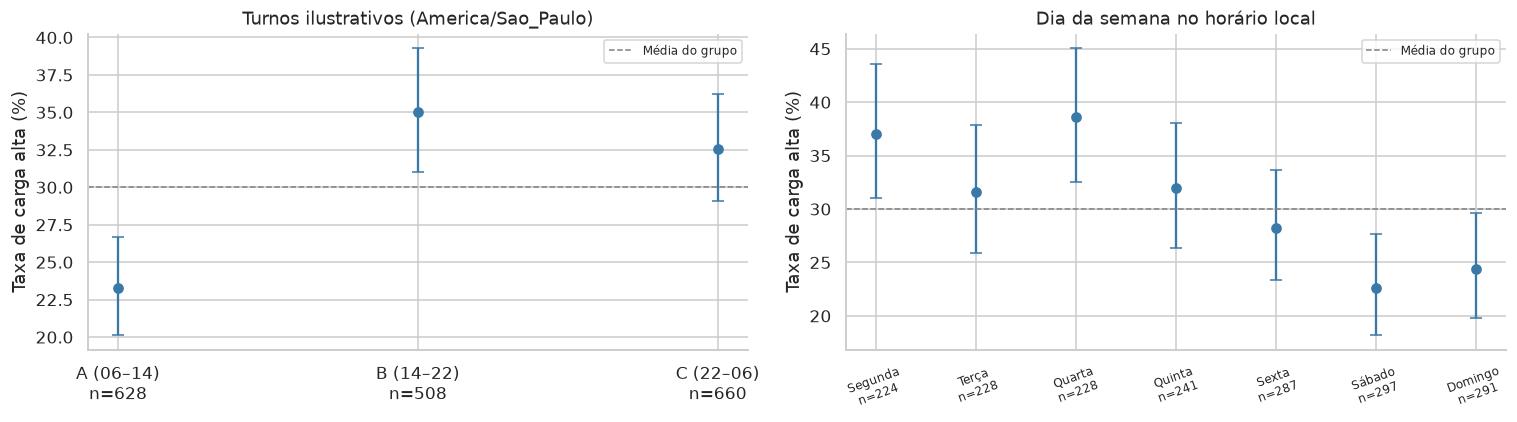

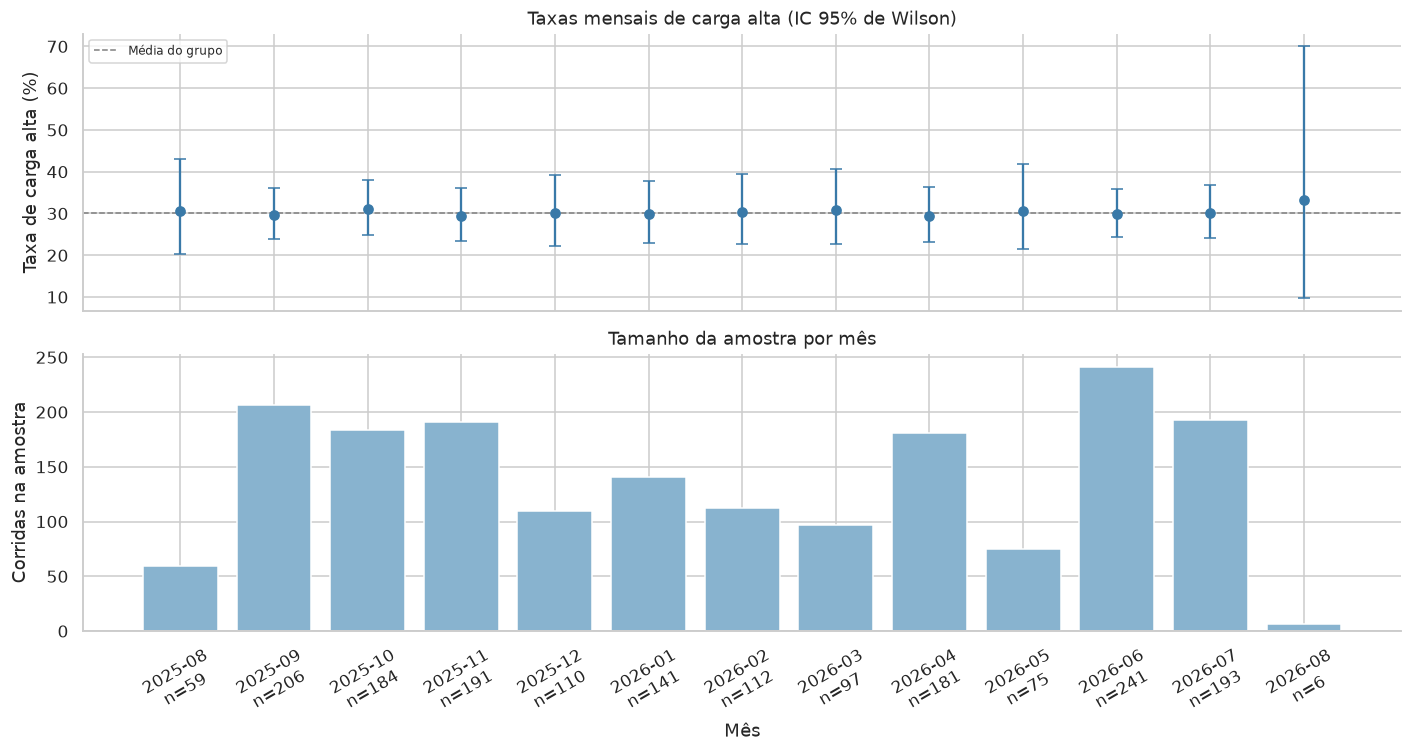

,n_all,rate_all,n_span_le_24h,rate_span_le_24h
shift,,,,
A (06–14),628,0.232,618,0.231
B (14–22),508,0.350,500,0.354
C (22–06),660,0.326,658,0.327


**Leitura temporal:** com as hipóteses de fuso e turnos adotadas, as taxas são A (06–14): 23.2% (n=628); B (14–22): 35.0% (n=508); C (22–06): 32.6% (n=660). Meses com ao menos 30 corridas variam de 29.3% a 31.0%. A amostra não mostra tendência mensal clara; confirme a cobertura da extração e as mudanças de receita antes de interpretar diferenças entre turnos.

,heats,complete_two_baskets_share,solid_mass_mean_t,light_share_mean,volume_coverage_mean,long_timestamp_span_share
month,,,,,,
2025-08,59,0.949,93.482,0.297,1.000,0.051
2025-09,206,0.951,90.888,0.313,0.999,0.015
2025-10,184,0.957,93.154,0.305,1.000,0.016
2025-11,191,0.969,93.751,0.287,1.000,0.010
2025-12,110,0.964,94.828,0.326,1.000,0.000
2026-01,141,0.986,101.690,0.295,1.000,0.007
2026-02,112,0.982,105.755,0.337,1.000,0.018
2026-03,97,0.969,95.323,0.335,1.000,0.010
2026-04,181,0.956,95.475,0.335,1.000,0.006


In [14]:
time_audit = enriched.groupby('cd_corrida')['consumed_at_utc'].agg(first='min', last='max', dated_records='count')
time_audit['span_hours'] = (time_audit['last'] - time_audit['first']).dt.total_seconds()/3600
time_audit['span_over_24h'] = time_audit['span_hours'].gt(24)
heat_start = active.loc[active.nu_carregamento == 1].groupby('cd_corrida')['consumed_at_utc'].min()
heat_table['heat_start_utc'] = heat_table['cd_corrida'].map(heat_start)
heat_table['heat_start_local'] = heat_table['heat_start_utc'].dt.tz_convert(LOCAL_TZ)
heat_table['timestamp_span_hours'] = heat_table['cd_corrida'].map(time_audit['span_hours'])
heat_table['timestamp_span_over_24h'] = heat_table['cd_corrida'].map(time_audit['span_over_24h'])
display(time_audit['span_hours'].describe(percentiles=[.9, .95, .99]).to_frame())
display(time_audit.nlargest(8, 'span_hours'))
display(Markdown(f'Cobertura dos horários locais: **{heat_table.heat_start_local.notna().sum():,}/{len(heat_table):,} corridas**; '
    f'inícios entre **{heat_table.heat_start_local.min():%Y-%m-%d} e '
    f'{heat_table.heat_start_local.max():%Y-%m-%d}**. '
    f'**{time_audit.span_over_24h.sum()} corridas** têm intervalo de consumo acima de 24 horas.'))

temporal = heat_table.loc[heat_table.heat_start_local.notna()].copy()
hours = temporal['heat_start_local'].dt.hour
temporal['shift'] = np.select([hours.between(6, 13), hours.between(14, 21)],
                               ['A (06–14)', 'B (14–22)'], default='C (22–06)')
temporal['weekday'] = pd.Categorical(
    temporal['heat_start_local'].dt.dayofweek.map(dict(enumerate(
        ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']))),
    categories=['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo'], ordered=True)
temporal['month'] = temporal['heat_start_local'].dt.strftime('%Y-%m')
shift_rates = rate_table(temporal, 'shift')
weekday_rates = rate_table(temporal, 'weekday')
monthly_rates = rate_table(temporal, 'month')
monthly_rates['downtime_minutes'] = temporal.groupby('month')['qt_segundos_parada_carga_alta'].sum()/60
display(shift_rates, weekday_rates, monthly_rates)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_rates(shift_rates, axes[0], f'Turnos ilustrativos ({LOCAL_TZ})', temporal.is_carga_alta.mean())
plot_rates(weekday_rates, axes[1], 'Dia da semana no horário local', temporal.is_carga_alta.mean())
axes[1].tick_params(axis='x', rotation=20, labelsize=8)
mostrar_graficos()

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
plot_rates(monthly_rates, axes[0], 'Taxas mensais de carga alta (IC 95% de Wilson)', temporal.is_carga_alta.mean())
axes[1].bar(np.arange(len(monthly_rates)), monthly_rates['n'], color='#88b3cf')
axes[1].set(ylabel='Corridas na amostra', xlabel='Mês', title='Tamanho da amostra por mês')
axes[1].tick_params(axis='x', rotation=30)
mostrar_graficos()

temporal_clean = temporal.loc[~temporal.timestamp_span_over_24h]
shift_sensitivity = shift_rates[['n', 'rate']].join(
    rate_table(temporal_clean, 'shift')[['n', 'rate']], lsuffix='_all', rsuffix='_span_le_24h')
display(shift_sensitivity)
shift_description = '; '.join(f'{shift}: {row.rate:.1%} (n={int(row.n)})'
                              for shift, row in shift_rates.iterrows())
larger_months = monthly_rates.loc[monthly_rates.n >= 30]
display(Markdown(f'**Leitura temporal:** com as hipóteses de fuso e turnos adotadas, '
    f'as taxas são {shift_description}. Meses com ao menos 30 corridas variam de '
    f'{larger_months.rate.min():.1%} a {larger_months.rate.max():.1%}. '
    'A amostra não mostra tendência mensal clara; confirme a cobertura da extração '
    'e as mudanças de receita antes de interpretar diferenças entre turnos.'))

# Conferir mudanças de receita e de cobertura ao longo do tempo.
temporal_recipe = temporal.groupby('month').agg(
    heats=('cd_corrida', 'size'), complete_two_baskets_share=('complete_two_baskets', 'mean'),
    solid_mass_mean_t=('solid_weight_t', 'mean'), light_share_mean=('solid_light_share', 'mean'),
    volume_coverage_mean=('solid_density_coverage', 'mean'),
    long_timestamp_span_share=('timestamp_span_over_24h', 'mean'))
display(temporal_recipe)


## 9. Achados e próximos passos

Os cinco achados abaixo são calculados a partir da análise. Considere a magnitude das associações e os denominadores: não há teste confirmatório nem modelo preditivo treinado.


In [15]:
both_events = response[['is_carga_alta_carregamento_1', 'is_carga_alta_carregamento_2']].eq(1).all(axis=1).sum()
complete_rates = rate_table(heat_table, 'complete_two_baskets')
missing_rate = complete_rates.loc[False, 'rate'] if False in complete_rates.index else np.nan
complete_rate = complete_rates.loc[True, 'rate'] if True in complete_rates.index else np.nan
volume_summary = '; '.join(
    f'carregamento {i}: r={associations.loc[(associations.charge == i) & (associations.feature == "volume_est_m3"), "point_biserial_r"].iloc[0]:+.3f}'
    for i in [1, 2])
strongest_summary = '; '.join(
    f'carregamento {i}: {FEATURE_LABELS[row.feature]} (r={row.point_biserial_r:+.3f})'
    for i in [1, 2]
    for row in [associations.loc[associations.charge == i].sort_values('abs_r', ascending=False).iloc[0]])
insights = [
    f'**Frequência dos eventos.** {response.is_carga_alta.sum():,}/{len(response):,} corridas '
    f'({response.is_carga_alta.mean():.1%}) têm carga alta. As taxas são '
    f'{response.is_carga_alta_carregamento_1.mean():.1%} no carregamento 1 e '
    f'{response.is_carga_alta_carregamento_2.mean():.1%} no 2; {both_events} corridas têm ambos os eventos.',
    f'**Tempo de parada.** A amostra soma {downtime_minutes:,.1f} minutos. Entre as corridas afetadas, '
    f'a mediana é {positive_stops.median():.0f}s, o percentil 95 é '
    f'{positive_stops.quantile(.95):.0f}s e o máximo é {positive_stops.max():.0f}s. '
    'O impacto financeiro depende do custo por minuto e da fração de parada evitável.',
    f'**Hipótese do volume.** Correlações do volume estimado: {volume_summary}. '
    f'Maiores correlações absolutas entre as características examinadas: {strongest_summary}. '
    'A sobreposição das distribuições e as taxas por quintil ajudam a avaliar a hipótese, '
    'mas não validam um limiar de previsão.',
    f'**Cestos ausentes.** {len(missing_charge2)} corridas não têm registros do carregamento 2, '
    f'incluindo {missing_charge2.is_carga_alta_carregamento_2.sum()} com evento nesse carregamento. '
    f'A taxa de carga alta é {missing_rate:.1%} nas corridas incompletas e {complete_rate:.1%} '
    'nas completas; restringir a análise muda a população observada.',
    f'**Qualidade e tempo.** Foram removidas {len(raw["layers"])-len(layers)} linhas idênticas; '
    f'{len(unknown)} códigos de material não têm cadastro; '
    f'{charge3_anomalies.cd_corrida.nunique()} corridas têm sólidos no carregamento 3 e '
    f'{time_audit.span_over_24h.sum()} têm intervalo de consumo acima de 24h. '
    'Esclareça esses pontos com a equipe de processo antes de usar as variáveis em produção.',
]
display(Markdown('\n\n'.join(f'{i}. {value}' for i, value in enumerate(insights, 1))))


1. **Frequência dos eventos.** 541/1,799 corridas (30.1%) têm carga alta. As taxas são 14.3% no carregamento 1 e 17.1% no 2; 25 corridas têm ambos os eventos.

2. **Tempo de parada.** A amostra soma 2,207.6 minutos. Entre as corridas afetadas, a mediana é 181s, o percentil 95 é 714s e o máximo é 1244s. O impacto financeiro depende do custo por minuto e da fração de parada evitável.

3. **Hipótese do volume.** Correlações do volume estimado: carregamento 1: r=+0.023; carregamento 2: r=-0.035. Maiores correlações absolutas entre as características examinadas: carregamento 1: Proporção de pesados (r=-0.186); carregamento 2: Proporção de pesados (r=-0.268). A sobreposição das distribuições e as taxas por quintil ajudam a avaliar a hipótese, mas não validam um limiar de previsão.

4. **Cestos ausentes.** 97 corridas não têm registros do carregamento 2, incluindo 7 com evento nesse carregamento. A taxa de carga alta é 51.5% nas corridas incompletas e 28.8% nas completas; restringir a análise muda a população observada.

5. **Qualidade e tempo.** Foram removidas 2 linhas idênticas; 2 códigos de material não têm cadastro; 6 corridas têm sólidos no carregamento 3 e 20 têm intervalo de consumo acima de 24h. Esclareça esses pontos com a equipe de processo antes de usar as variáveis em produção.

### Antes de modelar

1. Confirmar unidades, densidades, fuso, turnos e cobertura da extração. Esclarecer posições repetidas, materiais RECC/RECG, cestos ausentes e sólidos no carregamento 3. Grandes totais de gusa podem representar múltiplos vazamentos ou correções.
2. Testar massa, volume, densidade efetiva, proporções de materiais/classes e ordem das camadas. Comparar o ganho em períodos futuros, sem selecionar variáveis apenas pela correlação nesta amostra.
3. Definir o momento da previsão e usar somente informações disponíveis antes da decisão. Identificadores, paradas, eventos atuais e registros posteriores não entram como preditores.
4. Separar treino e avaliação por corrida e tempo; manter os dois cestos da mesma corrida juntos. Ajustar imputação, codificação e limiares somente no treino; definir como tratar cestos ausentes.
5. Comparar uma referência de classe majoritária com modelos simples. Avaliar PR-AUC, revocação, precisão, calibração e custo por limiar. Mudanças operacionais exigem avaliação controlada.


## 10. Exportação

- `dataset_modelagem.csv`: uma linha por corrida da resposta, com eventos, características dos cestos, totais parciais e indicadores de qualidade.
- `dataset_carregamentos.csv`: uma linha por carregamento rotulado, inclusive quando faltam características, com o estado da junção.
- Tabelas de camadas, materiais, associações, taxas mensais e manifesto; `eda_metadata.json` registra hipóteses e candidatos a preditores.

Os arquivos são tabelas de análise, não matrizes prontas para treino. Selecione explicitamente os preditores disponíveis no momento da decisão. As camadas preservam pesos zero, materiais desconhecidos, horários originais e posições repetidas não idênticas.


In [16]:
OUT.mkdir(parents=True, exist_ok=True)
exports = {
    'dataset_modelagem.csv': heat_table,
    'dataset_carregamentos.csv': basket_join,
    'camadas_clean_enriched.csv': enriched,
    'materiais_clean.csv': materials,
    'associacoes_carregamentos.csv': associations.drop(columns='abs_r'),
    'taxas_mensais.csv': monthly_rates.reset_index(),
    'source_manifest.csv': manifest,
}
for filename, frame in exports.items():
    frame.to_csv(OUT / filename, index=False)
metadata = {
    'reference': 'data/Guia_EVCOMX_EDA.pdf',
    'versions': {'python': platform.python_version(), 'pandas': pd.__version__,
                 'numpy': np.__version__, 'matplotlib': matplotlib.__version__, 'seaborn': sns.__version__},
    'source_files': manifest.to_dict(orient='records'),
    'assumptions': {'raw_weight_unit': 'kg (confirmar com a fonte)', 'density_unit': 't/m3',
        'yield': 'fração, não pontos percentuais', 'timestamps': 'UTC, conforme sufixo Z da fonte',
        'local_timezone': LOCAL_TZ, 'illustrative_shifts': ['06–14', '14–22', '22–06'],
        'volume': 'soma de massa_t / densidade do cadastro; ausente se a cobertura da massa for incompleta',
        'active_layers': 'posições distintas com peso positivo, carregamentos 1 e 2',
        'duplicates': 'somente linhas idênticas removidas; demais posições repetidas mantidas'},
    'basket_predictor_candidates': features,
    'heat_predictor_candidates_for_retrospective_eda': heat_predictors,
    'exclude_from_predictors': ['cd_corrida', *flag_cols, *duration_cols,
                               'downtime_seconds', 'feature_match', 'heat_start_utc', 'heat_start_local'],
    'availability_note': 'Confirmar a disponibilidade de cada variável antes da decisão sobre o carregamento. '
                         'Usar dados da corrida completa ou do carregamento 2 para prever o carregamento 1 somente se já forem conhecidos.',
    'outcome_units': 'segundos',
}
(OUT / 'eda_metadata.json').write_text(json.dumps(metadata, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')

# Reler exportações para conferir chaves, ausências e integridade dos arquivos brutos.
saved_heats = pd.read_csv(OUT / 'dataset_modelagem.csv')
saved_baskets = pd.read_csv(OUT / 'dataset_carregamentos.csv')
assert len(saved_heats) == len(response) and saved_heats['cd_corrida'].is_unique
assert len(saved_baskets) == len(response)*2 and not saved_baskets.duplicated(keys).any()
assert saved_heats['c2_weight_t'].isna().sum() == len(missing_charge2)
assert saved_baskets.loc[saved_baskets.feature_match.eq('left_only'), 'weight_t'].isna().all()
for row in manifest.itertuples():
    assert hashlib.sha256((RAW / row.file).read_bytes()).hexdigest() == row.sha256
display(pd.DataFrame([{'artifact': path.name, 'bytes': path.stat().st_size}
                      for path in sorted(OUT.iterdir()) if path.name in {*exports, 'eda_metadata.json'}]))
print('Validados: uma linha por corrida/carregamento, cestos ausentes preservados e arquivos brutos intactos.')


Validados: uma linha por corrida/carregamento, cestos ausentes preservados e arquivos brutos intactos.


,artifact,bytes
0,associacoes_carregamentos.csv,4065
1,camadas_clean_enriched.csv,6523268
2,dataset_carregamentos.csv,954190
3,dataset_modelagem.csv,1513943
4,eda_metadata.json,2803
5,materiais_clean.csv,1326
6,source_manifest.csv,355
7,taxas_mensais.csv,1140
